# YOLOv8 ONNX Inference in C++17: parity, tests, benchmarks
C++ port of NB1's manual YOLOv8 pipeline: letterbox, HWC→CHW, decode, NMS written from scratch,
verified against Python at every stage, unit-tested, sanitizer-checked, benchmarked against Python.

**Results card →** the "Results card" section near the end. It runs after all measurements;
every number in it is read from `results.json` with the cell that produced it.

In [1]:
# C0 — install ONNX Runtime (CPU), pinned to NB1's version
!pip uninstall -y onnxruntime-gpu -q
!pip install -q onnxruntime==1.27.0
import onnxruntime as ort
print("onnxruntime", ort.__version__, ort.get_available_providers())

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.7/18.7 MB 65.6 MB/s eta 0:00:00
onnxruntime 1.27.0 ['AzureExecutionProvider', 'CPUExecutionProvider']


In [2]:
# C1 — results.json helper + Python-side environment record
import json, os, sys, glob, subprocess, re
import numpy as np, cv2, onnxruntime as ort

WORK = "/kaggle/working"
os.makedirs(f"{WORK}/cpp", exist_ok=True)
RESULTS = f"{WORK}/results.json"

def record(path, value, cell):
    """record('env.ort_python', '1.27.0', 'C1') -> nested key, stores value + producing cell."""
    R = json.load(open(RESULTS)) if os.path.exists(RESULTS) else {}
    d = R
    *parents, leaf = path.split(".")
    for p in parents:
        d = d.setdefault(p, {})
    d[leaf] = {"value": value, "cell": cell}
    json.dump(R, open(RESULTS, "w"), indent=2)
    print(f"[results] {path} = {value}  ({cell})")

record("env.python",        sys.version.split()[0], "C1")
record("env.ort_python",    ort.__version__,        "C1")
record("env.opencv_python", cv2.__version__,        "C1")
record("env.numpy",         np.__version__,         "C1")
print("ORT providers:", ort.get_available_providers())

print("\nONNX models visible in /kaggle/input:")
for p in sorted(glob.glob("/kaggle/input/**/*.onnx", recursive=True)):
    print("  ", p)

[results] env.python = 3.13.15  (C1)
[results] env.ort_python = 1.27.0  (C1)
[results] env.opencv_python = 4.14.0  (C1)
[results] env.numpy = 2.1.3  (C1)
ORT providers: ['AzureExecutionProvider', 'CPUExecutionProvider']

ONNX models visible in /kaggle/input:
   /kaggle/input/notebooks/rsingh16281/onnx-inference/yolov8m.onnx
   /kaggle/input/notebooks/rsingh16281/onnx-inference/yolov8n.onnx
   /kaggle/input/notebooks/rsingh16281/onnx-inference/yolov8s.onnx


In [3]:
%%bash
set -e
apt-get update -qq
apt-get install -y -qq libopencv-dev cmake pkg-config > /dev/null
echo "g++    : $(g++ --version | head -1)"
echo "cmake  : $(cmake --version | head -1)"
echo "opencv : $(pkg-config --modversion opencv4)"

g++    : g++ (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
cmake  : cmake version 3.31.10
opencv : 4.6.0


W: https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64/InRelease: Key is stored in legacy trusted.gpg keyring (/etc/apt/trusted.gpg), see the DEPRECATION section in apt-key(8) for details.
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [4]:
# C3 — prebuilt ORT C++ package (linux-x64), matched to the Python ORT version
import urllib.request, urllib.error, tarfile, platform

assert platform.machine() == "x86_64", platform.machine()
WANT    = ort.__version__
ORT_DIR = f"{WORK}/onnxruntime-linux-x64-{WANT}"
url = f"https://github.com/microsoft/onnxruntime/releases/download/v{WANT}/onnxruntime-linux-x64-{WANT}.tgz"

if not os.path.isdir(ORT_DIR):
    try:
        tgz, _ = urllib.request.urlretrieve(url, f"{WORK}/ort.tgz")
        tarfile.open(tgz).extractall(WORK)
        os.remove(tgz)
    except urllib.error.HTTPError as e:
        print(f"HTTP {e.code} for {url}\nRecent release tags:")
        rel = json.load(urllib.request.urlopen(
            "https://api.github.com/repos/microsoft/onnxruntime/releases?per_page=15"))
        for r in rel:
            print("  ", r["tag_name"])
        raise RuntimeError("No matching tag — set WANT to the nearest one and re-run.")

print("Package contents:", sorted(os.listdir(ORT_DIR)))
print("lib/            :", sorted(os.listdir(f"{ORT_DIR}/lib")))
assert os.path.exists(f"{ORT_DIR}/include/onnxruntime_cxx_api.h"), "C++ API header missing"
vfile = f"{ORT_DIR}/VERSION_NUMBER"
ort_cpp_ver = open(vfile).read().strip() if os.path.exists(vfile) else WANT

def sh(c):
    return subprocess.run(c, shell=True, capture_output=True, text=True).stdout.strip()

record("env.ort_cpp",    ort_cpp_ver,                          "C3")
record("env.gxx",        sh("g++ --version | head -1"),        "C3")
record("env.cmake",      sh("cmake --version | head -1"),      "C3")
record("env.opencv_cpp", sh("pkg-config --modversion opencv4"), "C3")
record("env.cpu_model",  sh("lscpu | grep 'Model name' | cut -d: -f2 | xargs"), "C3")
record("env.logical_cores", os.cpu_count(), "C3")

flags = set(re.search(r"^flags\s*:(.*)$", open("/proc/cpuinfo").read(), re.M).group(1).split())
record("env.isa", {f: (f in flags) for f in
       ["avx2", "avx512f", "avx512_vnni", "avx_vnni", "amx_int8", "amx_tile"]}, "C3")

/tmp/ipykernel_23/1411349796.py:12: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tarfile.open(tgz).extractall(WORK)


Package contents: ['GIT_COMMIT_ID', 'LICENSE', 'Privacy.md', 'README.md', 'ThirdPartyNotices.txt', 'VERSION_NUMBER', 'include', 'lib']
lib/            : ['cmake', 'libonnxruntime.so', 'libonnxruntime.so.1', 'libonnxruntime.so.1.27.0', 'libonnxruntime_providers_shared.so', 'pkgconfig']
[results] env.ort_cpp = 1.27.0  (C3)
[results] env.gxx = g++ (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0  (C3)
[results] env.cmake = cmake version 3.31.10  (C3)
[results] env.opencv_cpp = 4.6.0  (C3)
[results] env.cpu_model = Intel(R) Xeon(R) CPU @ 2.00GHz  (C3)
[results] env.logical_cores = 4  (C3)
[results] env.isa = {'avx2': True, 'avx512f': True, 'avx512_vnni': False, 'avx_vnni': False, 'amx_int8': False, 'amx_tile': False}  (C3)


In [5]:
# C4 — project layout + model paths
MODEL_DIR = os.path.dirname(glob.glob("/kaggle/input/**/yolov8n.onnx", recursive=True)[0])
MODELS = {v: f"{MODEL_DIR}/yolov8{v}.onnx" for v in "nsm"}
for d in ["cpp/include", "cpp/src", "cpp/tests"]:
    os.makedirs(f"{WORK}/{d}", exist_ok=True)
print(MODELS)

{'n': '/kaggle/input/notebooks/rsingh16281/onnx-inference/yolov8n.onnx', 's': '/kaggle/input/notebooks/rsingh16281/onnx-inference/yolov8s.onnx', 'm': '/kaggle/input/notebooks/rsingh16281/onnx-inference/yolov8m.onnx'}


In [6]:
%%writefile cpp/CMakeLists.txt
cmake_minimum_required(VERSION 3.16)
project(yolov8_cpp CXX)

set(CMAKE_CXX_STANDARD 17)
set(CMAKE_CXX_STANDARD_REQUIRED ON)
if(NOT CMAKE_BUILD_TYPE)
  set(CMAKE_BUILD_TYPE Release)
endif()

set(ORT_DIR "" CACHE PATH "Path to onnxruntime-linux-x64-<ver>")
option(SANITIZE "Build with AddressSanitizer + UBSan" OFF)

find_package(OpenCV REQUIRED COMPONENTS core imgproc imgcodecs dnn)

add_compile_options(-Wall -Wextra)
set(CMAKE_CXX_FLAGS_RELEASE "-O3")
set(CMAKE_CXX_FLAGS_DEBUG   "-O0 -g")
if(SANITIZE)
  add_compile_options(-fsanitize=address,undefined -fno-omit-frame-pointer)
  add_link_options(-fsanitize=address,undefined)
endif()

# every src/*.cpp except main.cpp -> core library (reused by tests later)
file(GLOB CORE_SRC ${CMAKE_SOURCE_DIR}/src/*.cpp)
list(REMOVE_ITEM CORE_SRC ${CMAKE_SOURCE_DIR}/src/main.cpp)
add_library(yolo_core STATIC ${CORE_SRC})
target_include_directories(yolo_core PUBLIC ${CMAKE_SOURCE_DIR}/include)
target_include_directories(yolo_core SYSTEM PUBLIC ${ORT_DIR}/include ${OpenCV_INCLUDE_DIRS})
target_link_libraries(yolo_core PUBLIC ${ORT_DIR}/lib/libonnxruntime.so ${OpenCV_LIBS})

add_executable(detector src/main.cpp)
target_link_libraries(detector PRIVATE yolo_core)
set_target_properties(detector PROPERTIES BUILD_RPATH ${ORT_DIR}/lib)

Writing cpp/CMakeLists.txt


In [7]:
%%writefile cpp/include/detector.hpp
// C5 — detector.hpp
#pragma once
#include <onnxruntime_cxx_api.h>
#include <cstdint>
#include <string>
#include <vector>

struct TensorInfo {
    std::string name;
    std::vector<int64_t> shape;          // -1 = dynamic dim
    ONNXTensorElementDataType type;
};

// RAII owner of the ORT environment + session.
// Ort:: types are move-only, so Detector is implicitly non-copyable.
class Detector {
public:
    Detector(const std::string& model_path, int intra_threads);

    const std::vector<TensorInfo>& inputs()  const { return inputs_; }
    const std::vector<TensorInfo>& outputs() const { return outputs_; }
    int intra_threads() const { return intra_threads_; }

    // One forward pass. `input` must hold exactly prod(input shape) floats.
    // ORT wraps this buffer WITHOUT copying, so it must stay alive until Run() returns.
    // The returned Ort::Value owns the output memory (allocated by ORT).
    std::vector<Ort::Value> run(std::vector<float>& input);

private:
    int intra_threads_;
    Ort::Env env_;               // must be declared BEFORE session_:
    Ort::SessionOptions opts_;   // members are initialised in declaration order,
    Ort::Session session_;       // and the session needs a live env + options
    Ort::MemoryInfo mem_ = Ort::MemoryInfo::CreateCpu(OrtArenaAllocator, OrtMemTypeDefault);
    std::vector<TensorInfo> inputs_, outputs_;
};

std::string shape_str(const std::vector<int64_t>& s);
const char* type_str(ONNXTensorElementDataType t);

Writing cpp/include/detector.hpp


In [8]:
%%writefile cpp/src/detector.cpp
// C6 — detector.cpp
#include "detector.hpp"
#include <sstream>
#include <stdexcept>

namespace {

Ort::SessionOptions make_opts(int intra_threads) {
    Ort::SessionOptions o;
    o.SetIntraOpNumThreads(intra_threads);   // threads inside one op (GEMM/conv)
    o.SetInterOpNumThreads(1);               // no parallelism across ops
    o.SetExecutionMode(ExecutionMode::ORT_SEQUENTIAL);
    o.SetGraphOptimizationLevel(GraphOptimizationLevel::ORT_ENABLE_ALL);
    return o;
}

std::vector<TensorInfo> read_io(Ort::Session& s, bool is_input) {
    Ort::AllocatorWithDefaultOptions alloc;
    const size_t n = is_input ? s.GetInputCount() : s.GetOutputCount();
    std::vector<TensorInfo> v;
    for (size_t i = 0; i < n; ++i) {
        Ort::AllocatedStringPtr name = is_input ? s.GetInputNameAllocated(i, alloc)
                                                : s.GetOutputNameAllocated(i, alloc);
        Ort::TypeInfo ti = is_input ? s.GetInputTypeInfo(i) : s.GetOutputTypeInfo(i);
        auto tsi = ti.GetTensorTypeAndShapeInfo();
        v.push_back({name.get(), tsi.GetShape(), tsi.GetElementType()});
    }
    return v;
}

}  // namespace

Detector::Detector(const std::string& model_path, int intra_threads)
    : intra_threads_(intra_threads),
      env_(ORT_LOGGING_LEVEL_WARNING, "yolov8"),
      opts_(make_opts(intra_threads)),
      session_(env_, model_path.c_str(), opts_),
      inputs_(read_io(session_, true)),
      outputs_(read_io(session_, false)) {}

std::vector<Ort::Value> Detector::run(std::vector<float>& input) {
    const auto& in = inputs_[0];
    size_t expected = 1;
    for (int64_t d : in.shape) {
        if (d <= 0) throw std::runtime_error("dynamic input dim not supported: " + shape_str(in.shape));
        expected *= static_cast<size_t>(d);
    }
    if (input.size() != expected)
        throw std::runtime_error("input has " + std::to_string(input.size()) +
                                 " floats, model expects " + std::to_string(expected));

    // No-copy view: ORT reads directly from input.data(); we keep ownership.
    Ort::Value x = Ort::Value::CreateTensor<float>(mem_, input.data(), input.size(),
                                                   in.shape.data(), in.shape.size());
    const char* in_names[]  = {inputs_[0].name.c_str()};
    const char* out_names[] = {outputs_[0].name.c_str()};
    return session_.Run(Ort::RunOptions{nullptr}, in_names, &x, 1, out_names, 1);
}

std::string shape_str(const std::vector<int64_t>& s) {
    std::ostringstream os;
    for (size_t i = 0; i < s.size(); ++i) os << (i ? "x" : "") << s[i];
    return os.str();
}

const char* type_str(ONNXTensorElementDataType t) {
    switch (t) {
        case ONNX_TENSOR_ELEMENT_DATA_TYPE_FLOAT:   return "float32";
        case ONNX_TENSOR_ELEMENT_DATA_TYPE_FLOAT16: return "float16";
        case ONNX_TENSOR_ELEMENT_DATA_TYPE_UINT8:   return "uint8";
        case ONNX_TENSOR_ELEMENT_DATA_TYPE_INT8:    return "int8";
        case ONNX_TENSOR_ELEMENT_DATA_TYPE_INT64:   return "int64";
        default:                                    return "other";
    }
}

Writing cpp/src/detector.cpp


In [9]:
%%writefile cpp/src/main.cpp
#include "detector.hpp"
#include <iostream>
#include <map>
#include <stdexcept>

static std::map<std::string, std::string> parse_args(int argc, char** argv) {
    std::map<std::string, std::string> a;
    for (int i = 1; i < argc; ++i) {
        std::string k = argv[i];
        if (k.rfind("--", 0) != 0) throw std::runtime_error("bad arg: " + k);
        bool has_val = i + 1 < argc && std::string(argv[i + 1]).rfind("--", 0) != 0;
        a[k.substr(2)] = has_val ? argv[++i] : "1";
    }
    return a;
}

int main(int argc, char** argv) {
    try {
        auto a = parse_args(argc, argv);
        if (!a.count("model")) {
            std::cerr << "usage: detector --model X.onnx [--threads N]\n";
            return 2;
        }
        int threads = a.count("threads") ? std::stoi(a["threads"]) : 1;

        std::cout << "ORT_CPP_VERSION " << OrtGetApiBase()->GetVersionString() << "\n";
        Detector det(a["model"], threads);
        for (auto& t : det.inputs())
            std::cout << "IO input "  << t.name << " " << shape_str(t.shape) << " " << type_str(t.type) << "\n";
        for (auto& t : det.outputs())
            std::cout << "IO output " << t.name << " " << shape_str(t.shape) << " " << type_str(t.type) << "\n";
        std::cout << "THREADS intra=" << det.intra_threads() << "\n";
    } catch (const Ort::Exception& e) {
        std::cerr << "ORT error: " << e.what() << "\n"; return 1;
    } catch (const std::exception& e) {
        std::cerr << "error: " << e.what() << "\n"; return 1;
    }
    return 0;
}

Writing cpp/src/main.cpp


In [10]:
!cmake -S cpp -B build -DCMAKE_BUILD_TYPE=Release -DORT_DIR={ORT_DIR}
!cmake --build build -j4

-- The CXX compiler identification is GNU 13.3.0
-- Detecting CXX compiler ABI info
-- Detecting CXX compiler ABI info - done
-- Check for working CXX compiler: /usr/bin/c++ - skipped
-- Detecting CXX compile features
-- Detecting CXX compile features - done
-- Found OpenCV: /usr (found version "4.6.0") found components: core imgproc imgcodecs dnn
-- Configuring done (0.6s)
-- Generating done (0.0s)
-- Build files have been written to: /kaggle/working/build
[ 25%] Building CXX object CMakeFiles/yolo_core.dir/src/detector.cpp.o
[ 50%] Linking CXX static library libyolo_core.a
[ 50%] Built target yolo_core
[ 75%] Building CXX object CMakeFiles/detector.dir/src/main.cpp.o
[100%] Linking CXX executable detector
[100%] Built target detector


In [11]:
# C9 — Gate: C++ reads images[1,3,640,640] / output0[1,84,8400] float32, same as Python ORT
r = subprocess.run([f"{WORK}/build/detector", "--model", MODELS["n"], "--threads", "1"],
                   capture_output=True, text=True)
print(r.stdout, r.stderr)
assert r.returncode == 0, "C++ binary failed"

cpp_io = {(p[1], p[2]): (p[3], p[4]) for p in (l.split() for l in r.stdout.splitlines()) if p[0] == "IO"}
expected = {("input", "images"): ("1x3x640x640", "float32"),
            ("output", "output0"): ("1x84x8400", "float32")}
assert cpp_io == expected, cpp_io

s = ort.InferenceSession(MODELS["n"], providers=["CPUExecutionProvider"])
py_io = {("input", t.name): "x".join(map(str, t.shape)) for t in s.get_inputs()}
py_io |= {("output", t.name): "x".join(map(str, t.shape)) for t in s.get_outputs()}
assert {k: v[0] for k, v in cpp_io.items()} == py_io, py_io
print("GATE 1a PASS: C++ and Python ORT see identical I/O")

record("model_io.yolov8n", {f"{k[0]}:{k[1]}": v[0] for k, v in cpp_io.items()}, "C9")

ORT_CPP_VERSION 1.27.0
IO input images 1x3x640x640 float32
IO output output0 1x84x8400 float32
THREADS intra=1
 
GATE 1a PASS: C++ and Python ORT see identical I/O
[results] model_io.yolov8n = {'input:images': '1x3x640x640', 'output:output0': '1x84x8400'}  (C9)


In [12]:
%%writefile cpp/include/preprocess.hpp
#pragma once
#include <opencv2/core.hpp>
#include <string>
#include <vector>

struct LetterboxInfo {
    double ratio = 1.0;              // size / max(h, w)
    int new_w = 0, new_h = 0;
    int pad_left = 0, pad_top = 0;   // integer offsets actually used for the paste
    double dw = 0.0, dh = 0.0;       // float padding exactly as NB1 returns it (used for scale-back)
};

// Exact port of NB1 letterbox(): int() truncation, //2 centring, pad 114, INTER_LINEAR.
cv::Mat letterbox(const cv::Mat& bgr, int size, LetterboxInfo& info, int pad_value = 114);

// Divide        == NumPy `astype(float32) / 255.0`   (pipeline default)
// MulReciprocal == x * float(1/255)                  (layout check vs blobFromImage)
enum class Norm { Divide, MulReciprocal };

// Hand-written BGR->RGB, /255, HWC->CHW into a contiguous buffer of 3*H*W floats.
void to_chw_float(const cv::Mat& bgr_u8, std::vector<float>& out, Norm norm = Norm::Divide);

void write_bin(const std::string& path, const void* data, size_t bytes);

Writing cpp/include/preprocess.hpp


In [13]:
%%writefile cpp/src/preprocess.cpp
#include "preprocess.hpp"
#include <opencv2/imgproc.hpp>
#include <algorithm>
#include <fstream>
#include <stdexcept>

cv::Mat letterbox(const cv::Mat& bgr, int size, LetterboxInfo& info, int pad_value) {
    CV_Assert(!bgr.empty() && bgr.type() == CV_8UC3);
    const int h = bgr.rows, w = bgr.cols;
    info.ratio    = static_cast<double>(size) / std::max(h, w);  // Python float == IEEE double
    info.new_w    = static_cast<int>(w * info.ratio);             // int() truncates toward 0
    info.new_h    = static_cast<int>(h * info.ratio);
    info.pad_left = (size - info.new_w) / 2;                      // == Python // for non-negative ints
    info.pad_top  = (size - info.new_h) / 2;
    info.dw       = (size - info.new_w) / 2.0;
    info.dh       = (size - info.new_h) / 2.0;

    cv::Mat resized;
    cv::resize(bgr, resized, cv::Size(info.new_w, info.new_h), 0, 0, cv::INTER_LINEAR);
    cv::Mat canvas(size, size, CV_8UC3, cv::Scalar::all(pad_value));
    resized.copyTo(canvas(cv::Rect(info.pad_left, info.pad_top, info.new_w, info.new_h)));
    return canvas;
}

void to_chw_float(const cv::Mat& img, std::vector<float>& out, Norm norm) {
    CV_Assert(img.type() == CV_8UC3);
    const int H = img.rows, W = img.cols;
    const size_t HW = static_cast<size_t>(H) * W;
    out.resize(3 * HW);
    float* r = out.data();          // plane 0 = R
    float* g = r + HW;              // plane 1 = G
    float* b = g + HW;              // plane 2 = B
    const float inv = static_cast<float>(1.0 / 255.0);

    for (int y = 0; y < H; ++y) {
        const uint8_t* row = img.ptr<uint8_t>(y);   // per-row pointer: correct even if !isContinuous()
        for (int x = 0; x < W; ++x) {
            const uint8_t* px = row + 3 * x;         // HWC interleaved: B, G, R
            const size_t i = static_cast<size_t>(y) * W + x;
            if (norm == Norm::Divide) {
                r[i] = px[2] / 255.0f;  g[i] = px[1] / 255.0f;  b[i] = px[0] / 255.0f;
            } else {
                r[i] = px[2] * inv;     g[i] = px[1] * inv;     b[i] = px[0] * inv;
            }
        }
    }
}

void write_bin(const std::string& path, const void* data, size_t bytes) {
    std::ofstream f(path, std::ios::binary);
    if (!f) throw std::runtime_error("cannot open " + path);
    f.write(static_cast<const char*>(data), static_cast<std::streamsize>(bytes));
}

Writing cpp/src/preprocess.cpp


In [14]:
%%writefile cpp/src/main.cpp
// C12 — main.cpp v2 (preprocess check + inference + dumps)
#include "detector.hpp"
#include "preprocess.hpp"
#include <opencv2/dnn.hpp>
#include <opencv2/imgcodecs.hpp>
#include <algorithm>
#include <cmath>
#include <iomanip>
#include <iostream>
#include <map>
#include <stdexcept>

static std::map<std::string, std::string> parse_args(int argc, char** argv) {
    std::map<std::string, std::string> a;
    for (int i = 1; i < argc; ++i) {
        std::string k = argv[i];
        if (k.rfind("--", 0) != 0) throw std::runtime_error("bad arg: " + k);
        bool has_val = i + 1 < argc && std::string(argv[i + 1]).rfind("--", 0) != 0;
        a[k.substr(2)] = has_val ? argv[++i] : "1";
    }
    return a;
}

static void blob_check(const std::vector<float>& mine, const cv::Mat& blob, const char* tag) {
    CV_Assert(blob.isContinuous() && blob.total() == mine.size());
    const float* b = blob.ptr<float>();
    double max_d = 0.0; size_t n_diff = 0;
    for (size_t i = 0; i < mine.size(); ++i) {
        double d = std::fabs(static_cast<double>(mine[i]) - b[i]);
        if (d > 0) ++n_diff;
        max_d = std::max(max_d, d);
    }
    std::cout << "BLOBCHK " << tag << " max_abs_diff=" << max_d
              << " n_diff=" << n_diff << " of=" << mine.size() << "\n";
}

int main(int argc, char** argv) {
    try {
        auto a = parse_args(argc, argv);
        if (!a.count("model")) {
            std::cerr << "usage: detector --model X.onnx [--threads N] [--image img.jpg [--dump DIR]]\n";
            return 2;
        }
        int threads = a.count("threads") ? std::stoi(a["threads"]) : 1;

        std::cout << "ORT_CPP_VERSION " << OrtGetApiBase()->GetVersionString() << "\n";
        Detector det(a["model"], threads);
        for (auto& t : det.inputs())
            std::cout << "IO input "  << t.name << " " << shape_str(t.shape) << " " << type_str(t.type) << "\n";
        for (auto& t : det.outputs())
            std::cout << "IO output " << t.name << " " << shape_str(t.shape) << " " << type_str(t.type) << "\n";
        std::cout << "THREADS intra=" << det.intra_threads() << "\n";

        if (a.count("image")) {
            const int S = static_cast<int>(det.inputs()[0].shape[3]);   // 640, read from the model
            cv::Mat img = cv::imread(a["image"], cv::IMREAD_COLOR);
            if (img.empty()) throw std::runtime_error("cannot read " + a["image"]);
            CV_Assert(img.isContinuous());

            LetterboxInfo info;
            cv::Mat lb = letterbox(img, S, info);
            std::vector<float> chw_div, chw_mul;
            to_chw_float(lb, chw_div, Norm::Divide);
            to_chw_float(lb, chw_mul, Norm::MulReciprocal);

            std::cout << std::setprecision(17)
                      << "DECODED " << img.rows << "x" << img.cols << "\n"
                      << "LB ratio=" << info.ratio << " new_w=" << info.new_w << " new_h=" << info.new_h
                      << " pad_left=" << info.pad_left << " pad_top=" << info.pad_top
                      << " dw=" << info.dw << " dh=" << info.dh << "\n";

            cv::Mat blob = cv::dnn::blobFromImage(lb, 1.0 / 255.0, cv::Size(), cv::Scalar(), true, false);
            blob_check(chw_mul, blob, "mul_vs_blob");
            blob_check(chw_div, blob, "div_vs_blob");

            if (a.count("dump")) {
                const std::string d = a["dump"];
                write_bin(d + "/decoded_u8.bin",   img.data, img.total() * img.elemSize());
                write_bin(d + "/letterbox_u8.bin", lb.data,  lb.total() * lb.elemSize());
                write_bin(d + "/tensor_f32.bin",   chw_div.data(), chw_div.size() * sizeof(float));
                std::cout << "DUMPED " << d << "\n";
            }

            // ── inference (chw_div stays alive for the whole Run() call) ──
            auto out = det.run(chw_div);
            auto oinfo = out[0].GetTensorTypeAndShapeInfo();
            const float* y = out[0].GetTensorData<float>();
            const size_t n = oinfo.GetElementCount();
            std::cout << "OUT shape=" << shape_str(oinfo.GetShape()) << " n=" << n << "\n";
            if (a.count("dump")) write_bin(a["dump"] + "/output0_f32.bin", y, n * sizeof(float));
        }
    } catch (const Ort::Exception& e) {
        std::cerr << "ORT error: " << e.what() << "\n"; return 1;
    } catch (const std::exception& e) {
        std::cerr << "error: " << e.what() << "\n"; return 1;
    }
    return 0;
}

Overwriting cpp/src/main.cpp


In [15]:
# C13 — re-configure (GLOB picks up preprocess.cpp) and build
!cmake -S cpp -B build -DCMAKE_BUILD_TYPE=Release -DORT_DIR={ORT_DIR}
!cmake --build build -j4

-- Configuring done (0.0s)
-- Generating done (0.0s)
-- Build files have been written to: /kaggle/working/build
[ 20%] Building CXX object CMakeFiles/yolo_core.dir/src/preprocess.cpp.o
[ 40%] Linking CXX static library libyolo_core.a
[ 60%] Built target yolo_core
[ 80%] Building CXX object CMakeFiles/detector.dir/src/main.cpp.o
[100%] Linking CXX executable detector
[100%] Built target detector


In [16]:
# C14 — Gate 1: C++ preprocessing vs NB1 Python preprocessing, stage by stage
import urllib.request
BUS = f"{WORK}/bus.jpg"
if not os.path.exists(BUS):
    urllib.request.urlretrieve("https://ultralytics.com/images/bus.jpg", BUS)
DUMP = f"{WORK}/dump"; os.makedirs(DUMP, exist_ok=True)

r = subprocess.run([f"{WORK}/build/detector", "--model", MODELS["n"], "--image", BUS, "--dump", DUMP],
                   capture_output=True, text=True)
print(r.stdout, r.stderr); assert r.returncode == 0

# ── NB1 reference functions (verbatim logic) ──
def letterbox_py(img, new_size=640, color=(114, 114, 114)):
    h, w = img.shape[:2]
    ratio = new_size / max(h, w)
    new_w, new_h = int(w * ratio), int(h * ratio)
    img_resized = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_LINEAR)
    canvas = np.full((new_size, new_size, 3), color, dtype=np.uint8)
    pad_top, pad_left = (new_size - new_h) // 2, (new_size - new_w) // 2
    canvas[pad_top:pad_top + new_h, pad_left:pad_left + new_w] = img_resized
    return canvas, ratio, ((new_size - new_w) / 2, (new_size - new_h) / 2), (new_w, new_h, pad_left, pad_top)

def normalise_py(lb):
    x = cv2.cvtColor(lb, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
    return np.ascontiguousarray(x.transpose(2, 0, 1)[None])

# ── parse C++ letterbox info and assert identical geometry ──
lb_line = next(l for l in r.stdout.splitlines() if l.startswith("LB "))
cpp_lb = {k: float(v) for k, v in (kv.split("=") for kv in lb_line.split()[1:])}
img = cv2.imread(BUS)
lb_py, ratio, (dw, dh), (nw, nh, pl, pt) = letterbox_py(img)
assert (cpp_lb["ratio"], cpp_lb["new_w"], cpp_lb["new_h"], cpp_lb["pad_left"], cpp_lb["pad_top"],
        cpp_lb["dw"], cpp_lb["dh"]) == (ratio, nw, nh, pl, pt, dw, dh), (cpp_lb, ratio, nw, nh, pl, pt, dw, dh)
print("Letterbox geometry identical:", cpp_lb)

# ── staged diffs ──
def cmp(name, a, b):
    d = np.abs(a.astype(np.float64) - b.astype(np.float64))
    mx, n = float(d.max()), int((d > 0).sum())
    print(f"{name:28s} max_abs_diff={mx:.3e}  n_diff={n:>8d} / {d.size}")
    return {"max_abs_diff": mx, "n_diff": n, "n_total": int(d.size)}

dec_cpp = np.fromfile(f"{DUMP}/decoded_u8.bin",   np.uint8).reshape(img.shape)
lb_cpp  = np.fromfile(f"{DUMP}/letterbox_u8.bin", np.uint8).reshape(640, 640, 3)
x_cpp   = np.fromfile(f"{DUMP}/tensor_f32.bin",   np.float32).reshape(1, 3, 640, 640)
x_py    = normalise_py(lb_py)

s1 = cmp("1 JPEG decode (u8)",          dec_cpp, img)
s2 = cmp("2 letterbox (u8)",            lb_cpp,  lb_py)
s3 = cmp("3 tensor (f32) — Gate 1",     x_cpp,   x_py)
s4 = cmp("4 normalise only (C++ lb)",   x_cpp,   normalise_py(lb_cpp))   # isolates the CHW loop

blob = {p[1]: {kv.split("=")[0]: float(kv.split("=")[1]) for kv in p[2:]}
        for p in (l.split() for l in r.stdout.splitlines()) if p[0] == "BLOBCHK"}

record("parity.preproc_bus.decode_u8",      s1, "C14")
record("parity.preproc_bus.letterbox_u8",   s2, "C14")
record("parity.preproc_bus.tensor_f32",     s3, "C14")
record("parity.preproc_bus.normalise_only", s4, "C14")
record("parity.preproc_bus.blob_check",     blob, "C14")

assert s4["max_abs_diff"] == 0.0, "hand CHW loop disagrees with NumPy on identical input"
assert blob["mul_vs_blob"]["max_abs_diff"] == 0.0, "CHW layout disagrees with blobFromImage"
assert s3["max_abs_diff"] <= 1 / 255 + 1e-12, "GATE 1 FAIL"
print("GATE 1 PASS" + ("" if s3["max_abs_diff"] == 0 else " (non-zero — explain in Gotchas)"))

ORT_CPP_VERSION 1.27.0
IO input images 1x3x640x640 float32
IO output output0 1x84x8400 float32
THREADS intra=1
DECODED 1080x810
LB ratio=0.59259259259259256 new_w=480 new_h=640 pad_left=80 pad_top=0 dw=80 dh=0
BLOBCHK mul_vs_blob max_abs_diff=0 n_diff=0 of=1228800
BLOBCHK div_vs_blob max_abs_diff=5.9604644775390625e-08 n_diff=706796 of=1228800
DUMPED /kaggle/working/dump
OUT shape=1x84x8400 n=705600
 
Letterbox geometry identical: {'ratio': 0.5925925925925926, 'new_w': 480.0, 'new_h': 640.0, 'pad_left': 80.0, 'pad_top': 0.0, 'dw': 80.0, 'dh': 0.0}
1 JPEG decode (u8)           max_abs_diff=0.000e+00  n_diff=       0 / 2624400
2 letterbox (u8)             max_abs_diff=0.000e+00  n_diff=       0 / 1228800
3 tensor (f32) — Gate 1      max_abs_diff=0.000e+00  n_diff=       0 / 1228800
4 normalise only (C++ lb)    max_abs_diff=0.000e+00  n_diff=       0 / 1228800
[results] parity.preproc_bus.decode_u8 = {'max_abs_diff': 0.0, 'n_diff': 0, 'n_total': 2624400}  (C14)
[results] parity.preproc_bu

In [17]:
# C15 — Gate 2a: C++ raw output0 vs Python ORT on the identical tensor, same session settings
so = ort.SessionOptions()
so.intra_op_num_threads = 1
so.inter_op_num_threads = 1
so.execution_mode = ort.ExecutionMode.ORT_SEQUENTIAL
so.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL
sess_py = ort.InferenceSession(MODELS["n"], sess_options=so, providers=["CPUExecutionProvider"])

y_py  = sess_py.run(["output0"], {"images": x_py})[0]
y_cpp = np.fromfile(f"{DUMP}/output0_f32.bin", np.float32).reshape(y_py.shape)

raw_all   = cmp("output0 all channels",  y_cpp, y_py)
raw_box   = cmp("output0 box ch 0-3",    y_cpp[:, :4], y_py[:, :4])
raw_score = cmp("output0 score ch 4-83", y_cpp[:, 4:], y_py[:, 4:])

rng = {"box_min": float(y_py[:, :4].min()), "box_max": float(y_py[:, :4].max()),
       "score_min": float(y_py[:, 4:].min()), "score_max": float(y_py[:, 4:].max())}
print("value ranges:", rng)

record("parity.raw_output_bus.all",   raw_all,   "C15")
record("parity.raw_output_bus.box",   raw_box,   "C15")
record("parity.raw_output_bus.score", raw_score, "C15")
record("model.yolov8n_output_ranges_bus", rng, "C15")

# float32 spacing at 640 is ~6.1e-5, so box channels get an ulp-scaled tolerance
assert raw_score["max_abs_diff"] <= 1e-5, "score channels drift"
assert raw_box["max_abs_diff"]   <= 1e-4, "box channels drift"
print("GATE 2a PASS")

output0 all channels         max_abs_diff=0.000e+00  n_diff=       0 / 705600
output0 box ch 0-3           max_abs_diff=0.000e+00  n_diff=       0 / 33600
output0 score ch 4-83        max_abs_diff=0.000e+00  n_diff=       0 / 672000
value ranges: {'box_min': 2.8512277603149414, 'box_max': 637.2662963867188, 'score_min': 0.0, 'score_max': 0.8902071118354797}
[results] parity.raw_output_bus.all = {'max_abs_diff': 0.0, 'n_diff': 0, 'n_total': 705600}  (C15)
[results] parity.raw_output_bus.box = {'max_abs_diff': 0.0, 'n_diff': 0, 'n_total': 33600}  (C15)
[results] parity.raw_output_bus.score = {'max_abs_diff': 0.0, 'n_diff': 0, 'n_total': 672000}  (C15)
[results] model.yolov8n_output_ranges_bus = {'box_min': 2.8512277603149414, 'box_max': 637.2662963867188, 'score_min': 0.0, 'score_max': 0.8902071118354797}  (C15)
GATE 2a PASS


In [18]:
%%writefile cpp/include/postprocess.hpp
// C16 — postprocess.hpp
#pragma once
#include "preprocess.hpp"
#include <vector>

struct Det {
    float x1, y1, x2, y2;   // corners
    float score;            // max class score (YOLOv8 has no objectness)
    int   cls;              // argmax class, 0..79
    int   anchor;           // column in the 84x8400 output (used for cross-checks)
};

// (1, 4+C, N) channel-major output -> candidates with score > conf, in anchor order.
// Indexes the tensor in place: no transpose copy.
std::vector<Det> decode(const float* out, int num_ch, int num_anchors, float conf);

// IoU with guards: no overlap -> 0, zero/negative union -> 0.
double iou(const Det& a, const Det& b);

// Greedy per-class NMS, written from scratch. Output ordered by (class asc, score desc).
std::vector<Det> nms(const std::vector<Det>& dets, float iou_thr);

// Reference only: same per-class grouping, each class through cv::dnn::NMSBoxes (as NB1 does).
std::vector<Det> nms_opencv(const std::vector<Det>& dets, float iou_thr);

// Reverse letterbox exactly like NB1: float32 (x - pad) / ratio, clip to [0,W] / [0,H].
void scale_back(std::vector<Det>& dets, const LetterboxInfo& info, int orig_w, int orig_h);

extern const char* const COCO80[80];

Writing cpp/include/postprocess.hpp


In [19]:
%%writefile cpp/src/postprocess.cpp
// C17 — postprocess.cpp
#include "postprocess.hpp"
#include <opencv2/dnn.hpp>
#include <algorithm>
#include <map>
#include <numeric>

const char* const COCO80[80] = {
    "person","bicycle","car","motorcycle","airplane","bus","train","truck","boat",
    "traffic light","fire hydrant","stop sign","parking meter","bench","bird","cat",
    "dog","horse","sheep","cow","elephant","bear","zebra","giraffe","backpack",
    "umbrella","handbag","tie","suitcase","frisbee","skis","snowboard","sports ball",
    "kite","baseball bat","baseball glove","skateboard","surfboard","tennis racket",
    "bottle","wine glass","cup","fork","knife","spoon","bowl","banana","apple",
    "sandwich","orange","broccoli","carrot","hot dog","pizza","donut","cake","chair",
    "couch","potted plant","bed","dining table","toilet","tv","laptop","mouse",
    "remote","keyboard","cell phone","microwave","oven","toaster","sink","refrigerator",
    "book","clock","vase","scissors","teddy bear","hair drier","toothbrush"};

std::vector<Det> decode(const float* out, int num_ch, int N, float conf) {
    const int C = num_ch - 4;
    const size_t n = static_cast<size_t>(N);
    // Channel-major layout: element (ch, a) lives at out[ch * N + a].
    // Channels in the OUTER loop -> inner loop walks memory with stride 1.
    // (Per-anchor argmax would jump N floats = 33.6 KB between consecutive class reads.)
    std::vector<float> best(out + 4 * n, out + 5 * n);   // class-0 row as the starting max
    std::vector<int>   best_cls(n, 0);
    for (int c = 1; c < C; ++c) {
        const float* row = out + (4 + c) * n;
        for (int a = 0; a < N; ++a)
            if (row[a] > best[a]) { best[a] = row[a]; best_cls[a] = c; }  // strict > == np.argmax (first max wins)
    }
    const float* cx = out;
    const float* cy = out + n;
    const float* w  = out + 2 * n;
    const float* h  = out + 3 * n;

    std::vector<Det> dets;
    for (int a = 0; a < N; ++a) {
        if (!(best[a] > conf)) continue;                  // same strict > as NB1's mask
        const float hw = w[a] / 2.0f, hh = h[a] / 2.0f;   // float32 math, same as NumPy
        dets.push_back({cx[a] - hw, cy[a] - hh, cx[a] + hw, cy[a] + hh, best[a], best_cls[a], a});
    }
    return dets;
}

double iou(const Det& a, const Det& b) {
    const double iw = std::max(0.0, static_cast<double>(std::min(a.x2, b.x2)) - std::max(a.x1, b.x1));
    const double ih = std::max(0.0, static_cast<double>(std::min(a.y2, b.y2)) - std::max(a.y1, b.y1));
    const double inter  = iw * ih;
    const double area_a = std::max(0.0, static_cast<double>(a.x2) - a.x1) * std::max(0.0, static_cast<double>(a.y2) - a.y1);
    const double area_b = std::max(0.0, static_cast<double>(b.x2) - b.x1) * std::max(0.0, static_cast<double>(b.y2) - b.y1);
    const double uni = area_a + area_b - inter;
    return uni > 0.0 ? inter / uni : 0.0;
}

std::vector<Det> nms(const std::vector<Det>& dets, float iou_thr) {
    // Group by class, highest score first within a class. stable_sort keeps anchor order on ties.
    std::vector<int> order(dets.size());
    std::iota(order.begin(), order.end(), 0);
    std::stable_sort(order.begin(), order.end(), [&](int i, int j) {
        if (dets[i].cls != dets[j].cls) return dets[i].cls < dets[j].cls;
        return dets[i].score > dets[j].score;
    });

    std::vector<Det> keep;
    size_t cls_start = 0;   // where the current class's kept boxes begin inside `keep`
    for (int idx : order) {
        const Det& d = dets[idx];
        if (keep.empty() || keep.back().cls != d.cls) cls_start = keep.size();
        bool suppressed = false;
        for (size_t k = cls_start; k < keep.size(); ++k)    // compare only against same-class keepers
            if (iou(keep[k], d) > iou_thr) { suppressed = true; break; }
        if (!suppressed) keep.push_back(d);
    }
    return keep;
}

std::vector<Det> nms_opencv(const std::vector<Det>& dets, float iou_thr) {
    std::map<int, std::vector<int>> by_cls;
    for (int i = 0; i < static_cast<int>(dets.size()); ++i) by_cls[dets[i].cls].push_back(i);

    std::vector<Det> keep;
    for (const auto& kv : by_cls) {
        const std::vector<int>& idxs = kv.second;
        std::vector<cv::Rect2d> boxes;
        std::vector<float> scores;
        for (int i : idxs) {
            const Det& d = dets[i];
            const float w = d.x2 - d.x1, h = d.y2 - d.y1;   // float32, like NB1's xywh array
            boxes.emplace_back(d.x1, d.y1, w, h);
            scores.push_back(d.score);
        }
        std::vector<int> kept;
        cv::dnn::NMSBoxes(boxes, scores, 0.0f, iou_thr, kept);
        for (int k : kept) keep.push_back(dets[idxs[k]]);
    }
    return keep;
}

void scale_back(std::vector<Det>& dets, const LetterboxInfo& info, int orig_w, int orig_h) {
    const float pw = static_cast<float>(info.dw), ph = static_cast<float>(info.dh);
    const float r  = static_cast<float>(info.ratio);
    const float W  = static_cast<float>(orig_w),  H  = static_cast<float>(orig_h);
    for (auto& d : dets) {
        d.x1 = std::clamp((d.x1 - pw) / r, 0.0f, W);
        d.y1 = std::clamp((d.y1 - ph) / r, 0.0f, H);
        d.x2 = std::clamp((d.x2 - pw) / r, 0.0f, W);
        d.y2 = std::clamp((d.y2 - ph) / r, 0.0f, H);
    }
}

Writing cpp/src/postprocess.cpp


In [20]:
%%writefile cpp/src/main.cpp
// C18 — main.cpp v3 (preprocess check + inference + decode + scratch NMS + golden output)
#include "detector.hpp"
#include "postprocess.hpp"
#include "preprocess.hpp"
#include <opencv2/dnn.hpp>
#include <opencv2/imgcodecs.hpp>
#include <opencv2/imgproc.hpp>
#include <algorithm>
#include <cmath>
#include <cstdio>
#include <iomanip>
#include <iostream>
#include <map>
#include <stdexcept>

static std::map<std::string, std::string> parse_args(int argc, char** argv) {
    std::map<std::string, std::string> a;
    for (int i = 1; i < argc; ++i) {
        std::string k = argv[i];
        if (k.rfind("--", 0) != 0) throw std::runtime_error("bad arg: " + k);
        bool has_val = i + 1 < argc && std::string(argv[i + 1]).rfind("--", 0) != 0;
        a[k.substr(2)] = has_val ? argv[++i] : "1";
    }
    return a;
}

static void blob_check(const std::vector<float>& mine, const cv::Mat& blob, const char* tag) {
    CV_Assert(blob.isContinuous() && blob.total() == mine.size());
    const float* b = blob.ptr<float>();
    double max_d = 0.0; size_t n_diff = 0;
    for (size_t i = 0; i < mine.size(); ++i) {
        double d = std::fabs(static_cast<double>(mine[i]) - b[i]);
        if (d > 0) ++n_diff;
        max_d = std::max(max_d, d);
    }
    std::cout << "BLOBCHK " << tag << " max_abs_diff=" << max_d
              << " n_diff=" << n_diff << " of=" << mine.size() << "\n";
}

static std::vector<int> sorted_anchors(const std::vector<Det>& v) {
    std::vector<int> a;
    for (const auto& d : v) a.push_back(d.anchor);
    std::sort(a.begin(), a.end());
    return a;
}

int main(int argc, char** argv) {
    try {
        auto a = parse_args(argc, argv);
        if (!a.count("model")) {
            std::cerr << "usage: detector --model X.onnx [--threads N] [--image img.jpg "
                         "[--dump DIR] [--conf 0.25] [--iou 0.45] [--draw out.jpg]]\n";
            return 2;
        }
        const int   threads = a.count("threads") ? std::stoi(a["threads"]) : 1;
        const float conf    = a.count("conf") ? std::stof(a["conf"]) : 0.25f;
        const float iou_thr = a.count("iou")  ? std::stof(a["iou"])  : 0.45f;

        std::cout << "ORT_CPP_VERSION " << OrtGetApiBase()->GetVersionString() << "\n";
        Detector det(a["model"], threads);
        for (auto& t : det.inputs())
            std::cout << "IO input "  << t.name << " " << shape_str(t.shape) << " " << type_str(t.type) << "\n";
        for (auto& t : det.outputs())
            std::cout << "IO output " << t.name << " " << shape_str(t.shape) << " " << type_str(t.type) << "\n";
        std::cout << "THREADS intra=" << det.intra_threads() << "\n";

        if (a.count("image")) {
            const int S = static_cast<int>(det.inputs()[0].shape[3]);
            cv::Mat img = cv::imread(a["image"], cv::IMREAD_COLOR);
            if (img.empty()) throw std::runtime_error("cannot read " + a["image"]);
            CV_Assert(img.isContinuous());

            LetterboxInfo info;
            cv::Mat lb = letterbox(img, S, info);
            std::vector<float> chw_div, chw_mul;
            to_chw_float(lb, chw_div, Norm::Divide);
            to_chw_float(lb, chw_mul, Norm::MulReciprocal);

            std::cout << std::setprecision(17)
                      << "DECODED " << img.rows << "x" << img.cols << "\n"
                      << "LB ratio=" << info.ratio << " new_w=" << info.new_w << " new_h=" << info.new_h
                      << " pad_left=" << info.pad_left << " pad_top=" << info.pad_top
                      << " dw=" << info.dw << " dh=" << info.dh << "\n";

            cv::Mat blob = cv::dnn::blobFromImage(lb, 1.0 / 255.0, cv::Size(), cv::Scalar(), true, false);
            blob_check(chw_mul, blob, "mul_vs_blob");
            blob_check(chw_div, blob, "div_vs_blob");

            if (a.count("dump")) {
                const std::string d = a["dump"];
                write_bin(d + "/decoded_u8.bin",   img.data, img.total() * img.elemSize());
                write_bin(d + "/letterbox_u8.bin", lb.data,  lb.total() * lb.elemSize());
                write_bin(d + "/tensor_f32.bin",   chw_div.data(), chw_div.size() * sizeof(float));
                std::cout << "DUMPED " << d << "\n";
            }

            // ── inference (chw_div stays alive for the whole Run() call) ──
            auto out = det.run(chw_div);
            auto oinfo = out[0].GetTensorTypeAndShapeInfo();
            const auto oshape = oinfo.GetShape();
            const float* y = out[0].GetTensorData<float>();
            const size_t n = oinfo.GetElementCount();
            std::cout << "OUT shape=" << shape_str(oshape) << " n=" << n << "\n";
            if (a.count("dump")) write_bin(a["dump"] + "/output0_f32.bin", y, n * sizeof(float));

            // ── decode + NMS (scratch) + cross-check vs cv::dnn::NMSBoxes ──
            auto cands   = decode(y, static_cast<int>(oshape[1]), static_cast<int>(oshape[2]), conf);
            auto kept    = nms(cands, iou_thr);
            auto kept_cv = nms_opencv(cands, iou_thr);
            const bool same = sorted_anchors(kept) == sorted_anchors(kept_cv);
            std::cout << "CANDIDATES " << cands.size() << "\n"
                      << "NMSCHK equal=" << same << " scratch=" << kept.size()
                      << " opencv=" << kept_cv.size() << "\n";

            scale_back(kept, info, img.cols, img.rows);
            for (const auto& d : kept)
                std::cout << "DET " << d.cls << " " << d.score << " "
                          << static_cast<int>(d.x1) << " " << static_cast<int>(d.y1) << " "
                          << static_cast<int>(d.x2) << " " << static_cast<int>(d.y2) << " "
                          << COCO80[d.cls] << "\n";

            if (a.count("draw")) {
                cv::Mat vis = img.clone();
                for (const auto& d : kept) {
                    cv::Point p1(static_cast<int>(d.x1), static_cast<int>(d.y1));
                    cv::Point p2(static_cast<int>(d.x2), static_cast<int>(d.y2));
                    cv::rectangle(vis, p1, p2, cv::Scalar(0, 255, 0), 2);
                    char label[64];
                    std::snprintf(label, sizeof label, "%s %.2f", COCO80[d.cls], d.score);
                    cv::putText(vis, label, cv::Point(p1.x, std::max(p1.y - 5, 15)),
                                cv::FONT_HERSHEY_SIMPLEX, 0.6, cv::Scalar(0, 255, 0), 2);
                }
                cv::imwrite(a["draw"], vis);
                std::cout << "DRAWN " << a["draw"] << "\n";
            }
        }
    } catch (const Ort::Exception& e) {
        std::cerr << "ORT error: " << e.what() << "\n"; return 1;
    } catch (const std::exception& e) {
        std::cerr << "error: " << e.what() << "\n"; return 1;
    }
    return 0;
}

Overwriting cpp/src/main.cpp


In [21]:
# C19 — re-configure (GLOB picks up postprocess.cpp) and build main v3
!cmake -S cpp -B build -DCMAKE_BUILD_TYPE=Release -DORT_DIR={ORT_DIR}
!cmake --build build -j4

-- Configuring done (0.0s)
-- Generating done (0.0s)
-- Build files have been written to: /kaggle/working/build
[ 16%] Building CXX object CMakeFiles/yolo_core.dir/src/postprocess.cpp.o
[ 33%] Linking CXX static library libyolo_core.a
[ 66%] Built target yolo_core
[ 83%] Building CXX object CMakeFiles/detector.dir/src/main.cpp.o
[100%] Linking CXX executable detector
[100%] Built target detector


ORT_CPP_VERSION 1.27.0
IO input images 1x3x640x640 float32
IO output output0 1x84x8400 float32
THREADS intra=1
DECODED 1080x810
LB ratio=0.59259259259259256 new_w=480 new_h=640 pad_left=80 pad_top=0 dw=80 dh=0
BLOBCHK mul_vs_blob max_abs_diff=0 n_diff=0 of=1228800
BLOBCHK div_vs_blob max_abs_diff=5.9604644775390625e-08 n_diff=706796 of=1228800
OUT shape=1x84x8400 n=705600
CANDIDATES 46
NMSCHK equal=1 scratch=5 opencv=5
DET 0 0.89020711183547974 670 380 809 879 person
DET 0 0.88327902555465698 221 407 343 856 person
DET 0 0.87844228744506836 50 397 244 905 person
DET 0 0.43630784749984741 0 549 57 868 person
DET 5 0.8433692455291748 31 230 801 775 bus
DRAWN /kaggle/working/bus_cpp.jpg
 

candidates  C++=46  Py=46  NB1=46
 cls  C++ score   Py score  C++ box              Py box
   0   0.436308   0.436308  (0, 549, 57, 868)    (0, 549, 57, 868)
   0   0.878442   0.878442  (50, 397, 244, 905)  (50, 397, 244, 905)
   0   0.883279   0.883279  (221, 407, 343, 856) (221, 407, 343, 856)
   0   0

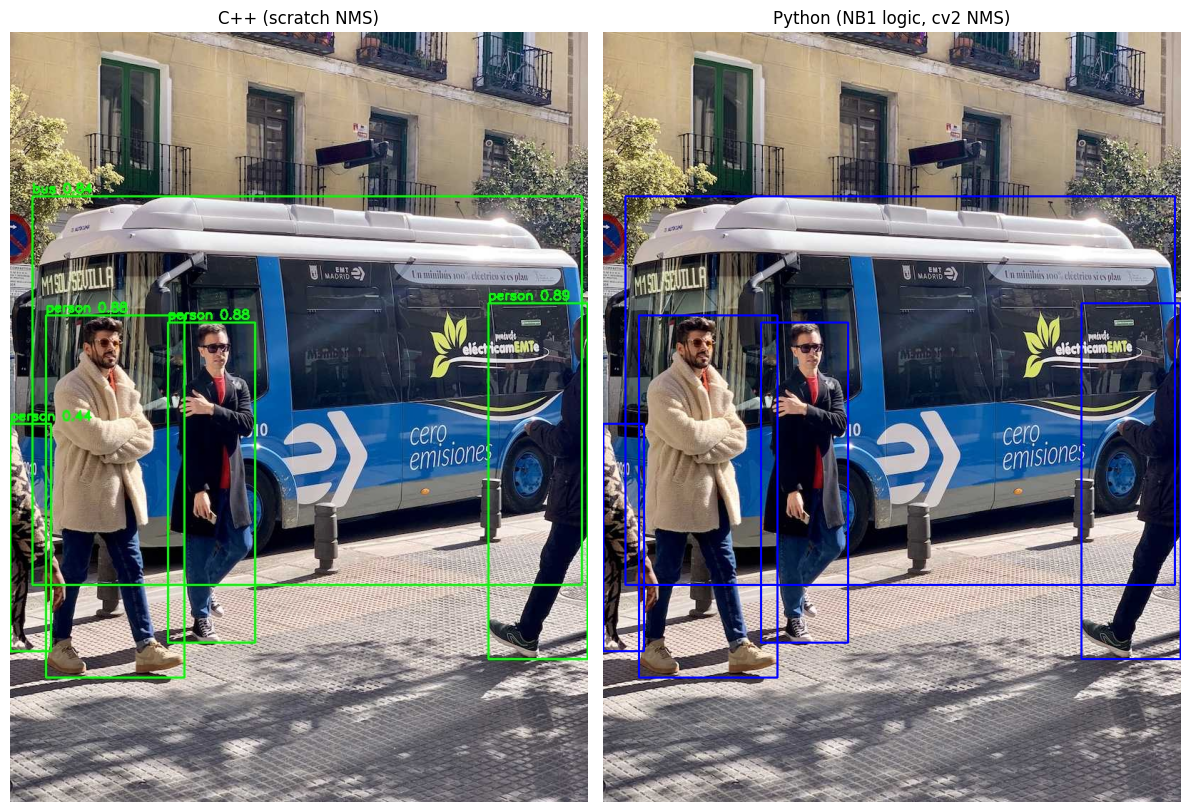

GATE 2b PASS (golden test)


In [22]:
# C20 — Gate 2b: golden test on bus.jpg
import matplotlib.pyplot as plt
DRAW = f"{WORK}/bus_cpp.jpg"
r = subprocess.run([f"{WORK}/build/detector", "--model", MODELS["n"], "--image", BUS,
                    "--conf", "0.25", "--iou", "0.45", "--draw", DRAW],
                   capture_output=True, text=True)
print(r.stdout, r.stderr); assert r.returncode == 0
lines = [l.split() for l in r.stdout.splitlines()]
n_cands_cpp = int(next(p[1] for p in lines if p[0] == "CANDIDATES"))
nms_equal   = next(p[1] for p in lines if p[0] == "NMSCHK") == "equal=1"
dets_cpp    = [(int(p[1]), float(p[2]), tuple(map(int, p[3:7]))) for p in lines if p[0] == "DET"]

# ── NB1 postprocessing, verbatim logic, on the Python raw output y_py (C15) ──
def postprocess_py(raw, ratio, pad_w, pad_h, orig_w, orig_h, conf=0.25, iou=0.45):
    preds = raw[0].T
    confs, cls = preds[:, 4:].max(axis=1), preds[:, 4:].argmax(axis=1)
    m = confs > conf
    b, c, k = preds[m, :4], confs[m], cls[m]
    xyxy = np.stack([b[:, 0] - b[:, 2] / 2, b[:, 1] - b[:, 3] / 2,
                     b[:, 0] + b[:, 2] / 2, b[:, 1] + b[:, 3] / 2], axis=1)
    xywh = xyxy.copy(); xywh[:, 2] = xyxy[:, 2] - xyxy[:, 0]; xywh[:, 3] = xyxy[:, 3] - xyxy[:, 1]
    keep = []
    for cid in np.unique(k):
        cm = k == cid
        idx = cv2.dnn.NMSBoxes(xywh[cm].tolist(), c[cm].tolist(), score_threshold=0.0, nms_threshold=iou)
        if len(idx):
            keep.extend(np.where(cm)[0][np.asarray(idx).flatten()].tolist())
    bx = xyxy[keep].astype(np.float32).copy()
    bx[:, 0] = np.clip((bx[:, 0] - pad_w) / ratio, 0, orig_w)
    bx[:, 1] = np.clip((bx[:, 1] - pad_h) / ratio, 0, orig_h)
    bx[:, 2] = np.clip((bx[:, 2] - pad_w) / ratio, 0, orig_w)
    bx[:, 3] = np.clip((bx[:, 3] - pad_h) / ratio, 0, orig_h)
    bx = bx.astype(np.int32)
    return int(m.sum()), [(int(k[i]), float(c[i]), tuple(bx[j].tolist())) for j, i in enumerate(keep)]

n_cands_py, dets_py = postprocess_py(y_py, ratio, dw, dh, img.shape[1], img.shape[0])

# ── NB1 committed golden (from NB1's saved output) ──
GOLDEN_NB1 = [(0, 0.890, (670, 380, 809, 879)), (0, 0.883, (221, 407, 343, 856)),
              (0, 0.878, (50, 397, 244, 905)),  (0, 0.436, (0, 549, 57, 868)),
              (5, 0.843, (31, 230, 801, 775))]

print(f"\ncandidates  C++={n_cands_cpp}  Py={n_cands_py}  NB1=46")
print(f"{'cls':>4} {'C++ score':>10} {'Py score':>10}  C++ box              Py box")
for dc, dp in zip(sorted(dets_cpp), sorted(dets_py)):
    print(f"{dc[0]:>4} {dc[1]:>10.6f} {dp[1]:>10.6f}  {str(dc[2]):20s} {dp[2]}")

# exact vs NB1 logic re-run here
same_set = sorted((d[0], d[2]) for d in dets_cpp) == sorted((d[0], d[2]) for d in dets_py)
max_score_py = max(abs(a[1] - b[1]) for a, b in zip(sorted(dets_cpp), sorted(dets_py)))

# vs NB1 committed numbers: same class, |score| <= 1e-3, every box coord within 1 px
max_box_nb1, max_score_nb1 = 0, 0.0
for g_cls, g_score, g_box in GOLDEN_NB1:
    cand = [d for d in dets_cpp if d[0] == g_cls]
    best = min(cand, key=lambda d: max(abs(u - v) for u, v in zip(d[2], g_box)))
    max_box_nb1   = max(max_box_nb1, max(abs(u - v) for u, v in zip(best[2], g_box)))
    max_score_nb1 = max(max_score_nb1, abs(best[1] - g_score))

golden = {"candidates": n_cands_cpp, "kept": len(dets_cpp), "nms_scratch_equals_opencv": nms_equal,
          "identical_to_nb1_logic": same_set, "max_score_diff_vs_nb1_logic": max_score_py,
          "max_box_diff_px_vs_nb1_committed": max_box_nb1, "max_score_diff_vs_nb1_committed": max_score_nb1}
record("parity.golden_bus", golden, "C20")

# side-by-side: C++ drawing vs NB1-logic drawing
vis_py = img.copy()
for c_, s_, (x1, y1, x2, y2) in dets_py:
    cv2.rectangle(vis_py, (x1, y1), (x2, y2), (255, 0, 0), 2)
fig, ax = plt.subplots(1, 2, figsize=(12, 8))
ax[0].imshow(cv2.cvtColor(cv2.imread(DRAW), cv2.COLOR_BGR2RGB)); ax[0].set_title("C++ (scratch NMS)")
ax[1].imshow(cv2.cvtColor(vis_py, cv2.COLOR_BGR2RGB));           ax[1].set_title("Python (NB1 logic, cv2 NMS)")
for x in ax: x.axis("off")
plt.tight_layout(); plt.show()

assert n_cands_cpp == n_cands_py == 46
assert nms_equal, "scratch NMS keep-set != cv::dnn::NMSBoxes"
assert same_set and max_score_py <= 1e-6
assert len(dets_cpp) == 5 and max_box_nb1 <= 1 and max_score_nb1 <= 1e-3
print("GATE 2b PASS (golden test)")

In [23]:
%%writefile cpp/CMakeLists.txt
# C21 — CMakeLists v2: core lib + detector CLI + unit tests
cmake_minimum_required(VERSION 3.16)
project(yolov8_cpp CXX)

set(CMAKE_CXX_STANDARD 17)
set(CMAKE_CXX_STANDARD_REQUIRED ON)
if(NOT CMAKE_BUILD_TYPE)
  set(CMAKE_BUILD_TYPE Release)
endif()

set(ORT_DIR "" CACHE PATH "Path to onnxruntime-linux-x64-<ver>")
option(SANITIZE "Build with AddressSanitizer + UBSan" OFF)

find_package(OpenCV REQUIRED COMPONENTS core imgproc imgcodecs dnn)

add_compile_options(-Wall -Wextra)
set(CMAKE_CXX_FLAGS_RELEASE "-O3")
set(CMAKE_CXX_FLAGS_DEBUG   "-O0 -g")
if(SANITIZE)
  add_compile_options(-fsanitize=address,undefined -fno-omit-frame-pointer)
  add_link_options(-fsanitize=address,undefined)
endif()

file(GLOB CORE_SRC ${CMAKE_SOURCE_DIR}/src/*.cpp)
list(REMOVE_ITEM CORE_SRC ${CMAKE_SOURCE_DIR}/src/main.cpp)
add_library(yolo_core STATIC ${CORE_SRC})
target_include_directories(yolo_core PUBLIC ${CMAKE_SOURCE_DIR}/include)
target_include_directories(yolo_core SYSTEM PUBLIC ${ORT_DIR}/include ${OpenCV_INCLUDE_DIRS})
target_link_libraries(yolo_core PUBLIC ${ORT_DIR}/lib/libonnxruntime.so ${OpenCV_LIBS})

add_executable(detector src/main.cpp)
target_link_libraries(detector PRIVATE yolo_core)

add_executable(test_postprocess tests/test_postprocess.cpp)
target_link_libraries(test_postprocess PRIVATE yolo_core)

set_target_properties(detector test_postprocess PROPERTIES BUILD_RPATH ${ORT_DIR}/lib)

Overwriting cpp/CMakeLists.txt


In [24]:
%%writefile cpp/tests/test_postprocess.cpp
// C22 — unit tests for decode / iou / nms (no framework; CHECK always runs, unlike assert under NDEBUG)
#include "postprocess.hpp"
#include <cmath>
#include <cstdio>
#include <vector>

static int g_pass = 0, g_fail = 0;
#define CHECK(cond) do { if (cond) ++g_pass; else { ++g_fail; \
    std::printf("FAIL %s:%d  %s\n", __FILE__, __LINE__, #cond); } } while (0)

static Det box(float x1, float y1, float x2, float y2, float s, int c, int anchor) {
    return {x1, y1, x2, y2, s, c, anchor};
}

static void test_identical() {
    Det a = box(0, 0, 10, 10, 0.9f, 0, 0), b = box(0, 0, 10, 10, 0.8f, 0, 1);
    CHECK(iou(a, b) == 1.0);
    auto k = nms({a, b}, 0.45f);
    CHECK(k.size() == 1 && k[0].anchor == 0);              // higher score survives
}

static void test_disjoint_and_touching() {
    Det a = box(0, 0, 10, 10, 0.9f, 0, 0), b = box(20, 20, 30, 30, 0.8f, 0, 1);
    Det t = box(10, 0, 20, 10, 0.7f, 0, 2);               // shares an edge with a
    CHECK(iou(a, b) == 0.0);
    CHECK(iou(a, t) == 0.0);
    CHECK(nms({a, b, t}, 0.45f).size() == 3);
}

static void test_iou_at_threshold() {
    // inter = 50, union = 100 -> IoU exactly 0.5 (exact in float and double; 0.45 would not be)
    Det a = box(0, 0, 10, 10, 0.9f, 0, 0), b = box(0, 0, 10, 5, 0.8f, 0, 1);
    CHECK(iou(a, b) == 0.5);
    CHECK(nms({a, b}, 0.50f).size() == 2);                 // suppress only if IoU > thr
    CHECK(nms({a, b}, 0.49f).size() == 1);
}

static void test_zero_area() {
    Det z  = box(5, 5, 5, 5, 0.9f, 0, 0);                  // degenerate point box
    Det a  = box(0, 0, 10, 10, 0.8f, 0, 1);
    Det z2 = box(5, 5, 5, 5, 0.7f, 0, 2);
    CHECK(iou(z, a) == 0.0 && !std::isnan(iou(z, a)));
    CHECK(iou(z, z2) == 0.0 && !std::isnan(iou(z, z2)));  // union 0 -> guarded, no 0/0 NaN
    CHECK(nms({z, a, z2}, 0.45f).size() == 3);
}

static void test_two_classes_overlap() {
    Det b = box(0, 0, 10, 10, 0.8f, 1, 1), a = box(0, 0, 10, 10, 0.9f, 0, 0);
    auto k = nms({b, a}, 0.45f);
    CHECK(k.size() == 2);                                   // different classes never suppress
    CHECK(k.size() == 2 && k[0].cls == 0 && k[1].cls == 1); // output ordered by class
}

static void test_empty() {
    CHECK(nms({}, 0.45f).empty());
}

static void test_decode() {
    const int N = 3, CH = 84;
    std::vector<float> out(CH * N, 0.0f);
    auto at = [&](int c, int a) -> float& { return out[c * N + a]; };   // channel-major (84, N)
    at(0, 0) = 50; at(1, 0) = 60; at(2, 0) = 20; at(3, 0) = 10; at(4 + 7, 0) = 0.6f;  // anchor 0 -> class 7
    at(4 + 2, 1) = 0.7f; at(4 + 9, 1) = 0.7f;   // anchor 1: tie -> first max (class 2), like np.argmax
    at(4 + 0, 2) = 0.25f;                        // anchor 2: exactly at conf -> rejected by strict >
    auto d = decode(out.data(), CH, N, 0.25f);
    CHECK(d.size() == 2);
    if (d.size() == 2) {
        CHECK(d[0].anchor == 0 && d[0].cls == 7);
        CHECK(d[0].x1 == 40 && d[0].y1 == 55 && d[0].x2 == 60 && d[0].y2 == 65);
        CHECK(d[1].anchor == 1 && d[1].cls == 2);
    }
}

int main() {
    test_identical();
    test_disjoint_and_touching();
    test_iou_at_threshold();
    test_zero_area();
    test_two_classes_overlap();
    test_empty();
    test_decode();
    std::printf("TESTS passed=%d failed=%d\n", g_pass, g_fail);
    return g_fail ? 1 : 0;
}

Writing cpp/tests/test_postprocess.cpp


In [25]:
# C23 — build Release (incl. tests) and run unit tests
!cmake -S cpp -B build -DCMAKE_BUILD_TYPE=Release -DORT_DIR={ORT_DIR}
!cmake --build build -j4

r = subprocess.run([f"{WORK}/build/test_postprocess"], capture_output=True, text=True)
print(r.stdout, r.stderr)
m = re.search(r"passed=(\d+) failed=(\d+)", r.stdout)
record("tests.unit_release", {"passed": int(m[1]), "failed": int(m[2])}, "C23")
assert r.returncode == 0 and int(m[2]) == 0, "unit tests failed"
print("UNIT TESTS PASS")

-- Configuring done (0.0s)
-- Generating done (0.0s)
-- Build files have been written to: /kaggle/working/build
[ 50%] Built target yolo_core
[ 62%] Building CXX object CMakeFiles/test_postprocess.dir/tests/test_postprocess.cpp.o
[ 87%] Built target detector
[100%] Linking CXX executable test_postprocess
[100%] Built target test_postprocess
TESTS passed=18 failed=0
 
[results] tests.unit_release = {'passed': 18, 'failed': 0}  (C23)
UNIT TESTS PASS


In [26]:
# C24 — Gate 2c: AddressSanitizer + UBSan clean run
!cmake -S cpp -B build-asan -DCMAKE_BUILD_TYPE=Debug -DSANITIZE=ON -DORT_DIR={ORT_DIR}
!cmake --build build-asan -j4

env = dict(os.environ,
           ASAN_OPTIONS="detect_leaks=1:halt_on_error=1",
           UBSAN_OPTIONS="print_stacktrace=1:halt_on_error=1")
runs = {
    "detector_bus": [f"{WORK}/build-asan/detector", "--model", MODELS["n"], "--image", BUS],
    "unit_tests":   [f"{WORK}/build-asan/test_postprocess"],
}
asan = {}
for name, cmd in runs.items():
    r = subprocess.run(cmd, capture_output=True, text=True, env=env)
    san = [l for l in r.stderr.splitlines() if "Sanitizer" in l or "runtime error" in l]
    print(f"── {name}: exit={r.returncode}")
    print(r.stdout[-700:])
    print(r.stderr[-3000:] if san else "no sanitizer messages")
    asan[name] = {"exit_code": r.returncode, "sanitizer_lines": len(san)}

record("tests.asan_ubsan", asan, "C24")
assert all(v["exit_code"] == 0 and v["sanitizer_lines"] == 0 for v in asan.values()), "sanitizer run not clean"
print("GATE 2c PASS (ASan + UBSan clean)")

-- The CXX compiler identification is GNU 13.3.0
-- Detecting CXX compiler ABI info
-- Detecting CXX compiler ABI info - done
-- Check for working CXX compiler: /usr/bin/c++ - skipped
-- Detecting CXX compile features
-- Detecting CXX compile features - done
-- Found OpenCV: /usr (found version "4.6.0") found components: core imgproc imgcodecs dnn
-- Configuring done (0.2s)
-- Generating done (0.0s)
-- Build files have been written to: /kaggle/working/build-asan
[ 25%] Building CXX object CMakeFiles/yolo_core.dir/src/postprocess.cpp.o
[ 25%] Building CXX object CMakeFiles/yolo_core.dir/src/detector.cpp.o
[ 37%] Building CXX object CMakeFiles/yolo_core.dir/src/preprocess.cpp.o
[ 50%] Linking CXX static library libyolo_core.a
[ 50%] Built target yolo_core
[ 62%] Building CXX object CMakeFiles/detector.dir/src/main.cpp.o
[ 75%] Building CXX object CMakeFiles/test_postprocess.dir/tests/test_postprocess.cpp.o
[ 87%] Linking CXX executable test_postprocess
[ 87%] Built target test_postproces

In [27]:
# C25 — locate COCO val2017, then scratch NMS == cv::dnn::NMSBoxes on 20 images, at demo AND eval settings
COCO_ANN = COCO_IMG_DIR = None
for root, dirs, files in os.walk("/kaggle/input"):
    dirs[:] = [d for d in dirs if d not in ("train2017", "test2017", "unlabeled2017")]   # skip huge dirs
    if "instances_val2017.json" in files:
        COCO_ANN = os.path.join(root, "instances_val2017.json")
    if os.path.basename(root) == "val2017" and any(f.endswith(".jpg") for f in files):
        COCO_IMG_DIR = root
print("annotations:", COCO_ANN)
print("val images :", COCO_IMG_DIR, "|", len(os.listdir(COCO_IMG_DIR)) if COCO_IMG_DIR else "NOT FOUND")
assert COCO_ANN and COCO_IMG_DIR, "COCO paths not found — paste this output"

all_val = sorted(f for f in os.listdir(COCO_IMG_DIR) if f.endswith(".jpg"))
rng = np.random.default_rng(0)
nms20 = sorted(rng.choice(all_val, 20, replace=False).tolist())

SETTINGS = {"demo": ("0.25", "0.45"), "eval": ("0.001", "0.7")}
nms_chk = {}
for tag, (c, i) in SETTINGS.items():
    n_eq, n_cands, n_kept, bad = 0, 0, 0, []
    for f in nms20:
        r = subprocess.run([f"{WORK}/build/detector", "--model", MODELS["n"],
                            "--image", f"{COCO_IMG_DIR}/{f}", "--conf", c, "--iou", i],
                           capture_output=True, text=True)
        assert r.returncode == 0, (f, r.stderr)
        p = dict(l.split(" ", 1) for l in r.stdout.splitlines() if l.startswith(("CANDIDATES", "NMSCHK")))
        eq = p["NMSCHK"].startswith("equal=1")
        n_eq += eq; n_cands += int(p["CANDIDATES"])
        n_kept += sum(l.startswith("DET ") for l in r.stdout.splitlines())
        if not eq: bad.append((f, p["NMSCHK"]))
    nms_chk[tag] = {"conf": float(c), "iou": float(i), "images": len(nms20), "equal": n_eq,
                    "total_candidates": n_cands, "total_kept": n_kept, "mismatches": bad}
    print(f"{tag:5s} conf={c:<6} iou={i:<4}  equal {n_eq}/{len(nms20)}  "
          f"candidates={n_cands:>6}  kept={n_kept:>5}  mismatches={bad}")

json.dump({"seed": 0, "files": nms20}, open(f"{WORK}/nms20_ids.json", "w"), indent=2)
record("parity.nms_vs_opencv_coco20", nms_chk, "C25")
assert all(v["equal"] == v["images"] for v in nms_chk.values()), "scratch NMS != NMSBoxes on some image"
print("NMS CROSS-CHECK PASS")

annotations: /kaggle/input/datasets/awsaf49/coco-2017-dataset/coco2017/annotations/instances_val2017.json
val images : /kaggle/input/datasets/awsaf49/coco-2017-dataset/coco2017/val2017 | 5000
demo  conf=0.25   iou=0.45  equal 20/20  candidates=   675  kept=   96  mismatches=[]
eval  conf=0.001  iou=0.7   equal 20/20  candidates=  9289  kept= 2999  mismatches=[]
[results] parity.nms_vs_opencv_coco20 = {'demo': {'conf': 0.25, 'iou': 0.45, 'images': 20, 'equal': 20, 'total_candidates': 675, 'total_kept': 96, 'mismatches': []}, 'eval': {'conf': 0.001, 'iou': 0.7, 'images': 20, 'equal': 20, 'total_candidates': 9289, 'total_kept': 2999, 'mismatches': []}}  (C25)
NMS CROSS-CHECK PASS


In [28]:
%%writefile cpp/include/coco.hpp
// C26 — coco.hpp: YOLO-80 -> COCO-91 ids, image ids from filenames, COCO results JSON
#pragma once
#include "postprocess.hpp"
#include <ostream>
#include <string>
#include <vector>

int coco80_to_coco91(int cls80);                    // throws std::out_of_range outside 0..79
long long coco_image_id(const std::string& path);   // ".../000000397133.jpg" -> 397133, non-numeric -> -1

// Appends dets in COCO results format: {"image_id","category_id","bbox":[x,y,w,h],"score"}.
// `first` tracks comma placement across calls.
void append_coco_json(std::ostream& os, long long image_id, const std::vector<Det>& dets, bool& first);

Writing cpp/include/coco.hpp


In [29]:
%%writefile cpp/src/coco.cpp
// C27 — coco.cpp
#include "coco.hpp"
#include <filesystem>
#include <iomanip>
#include <stdexcept>

static const int kCoco91[80] = {
     1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 13, 14, 15, 16, 17, 18, 19, 20, 21,
    22, 23, 24, 25, 27, 28, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44,
    46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65,
    67, 70, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 84, 85, 86, 87, 88, 89, 90};

int coco80_to_coco91(int c) {
    if (c < 0 || c >= 80) throw std::out_of_range("class index " + std::to_string(c));
    return kCoco91[c];
}

long long coco_image_id(const std::string& path) {
    const std::string stem = std::filesystem::path(path).stem().string();
    if (stem.empty() || stem.find_first_not_of("0123456789") != std::string::npos) return -1;
    return std::stoll(stem);
}

void append_coco_json(std::ostream& os, long long image_id, const std::vector<Det>& dets, bool& first) {
    os << std::setprecision(9);   // 9 significant digits round-trip any float32 exactly
    for (const auto& d : dets) {
        os << (first ? "\n" : ",\n")
           << "{\"image_id\":" << image_id
           << ",\"category_id\":" << coco80_to_coco91(d.cls)
           << ",\"bbox\":[" << d.x1 << "," << d.y1 << "," << (d.x2 - d.x1) << "," << (d.y2 - d.y1) << "]"
           << ",\"score\":" << d.score << "}";
        first = false;
    }
}

Writing cpp/src/coco.cpp


In [30]:
%%writefile cpp/tests/test_coco.cpp
// C28 — unit tests for the COCO helpers
#include "coco.hpp"
#include <cstdio>
#include <sstream>
#include <stdexcept>

static int g_pass = 0, g_fail = 0;
#define CHECK(cond) do { if (cond) ++g_pass; else { ++g_fail; \
    std::printf("FAIL %s:%d  %s\n", __FILE__, __LINE__, #cond); } } while (0)

int main() {
    CHECK(coco80_to_coco91(0)  == 1);    // person
    CHECK(coco80_to_coco91(5)  == 6);    // bus
    CHECK(coco80_to_coco91(11) == 13);   // stop sign: first gap (COCO id 12 unused)
    CHECK(coco80_to_coco91(79) == 90);   // toothbrush
    bool threw = false;
    try { coco80_to_coco91(80); } catch (const std::out_of_range&) { threw = true; }
    CHECK(threw);

    CHECK(coco_image_id("/x/val2017/000000397133.jpg") == 397133);
    CHECK(coco_image_id("bus.jpg") == -1);

    std::ostringstream os; bool first = true;
    append_coco_json(os, 42, {Det{10, 20, 40, 60, 0.5f, 5, 0}}, first);   // xyxy -> xywh, bus -> 6
    CHECK(os.str() == "\n{\"image_id\":42,\"category_id\":6,\"bbox\":[10,20,30,40],\"score\":0.5}");

    std::printf("TESTS passed=%d failed=%d\n", g_pass, g_fail);
    return g_fail ? 1 : 0;
}

Writing cpp/tests/test_coco.cpp


In [31]:
%%writefile cpp/CMakeLists.txt
# C29 — CMakeLists v3: core lib + detector CLI + one executable per tests/*.cpp
cmake_minimum_required(VERSION 3.16)
project(yolov8_cpp CXX)

set(CMAKE_CXX_STANDARD 17)
set(CMAKE_CXX_STANDARD_REQUIRED ON)
if(NOT CMAKE_BUILD_TYPE)
  set(CMAKE_BUILD_TYPE Release)
endif()

set(ORT_DIR "" CACHE PATH "Path to onnxruntime-linux-x64-<ver>")
option(SANITIZE "Build with AddressSanitizer + UBSan" OFF)

find_package(OpenCV REQUIRED COMPONENTS core imgproc imgcodecs dnn)

add_compile_options(-Wall -Wextra)
set(CMAKE_CXX_FLAGS_RELEASE "-O3")
set(CMAKE_CXX_FLAGS_DEBUG   "-O0 -g")
if(SANITIZE)
  add_compile_options(-fsanitize=address,undefined -fno-omit-frame-pointer)
  add_link_options(-fsanitize=address,undefined)
endif()

file(GLOB CORE_SRC ${CMAKE_SOURCE_DIR}/src/*.cpp)
list(REMOVE_ITEM CORE_SRC ${CMAKE_SOURCE_DIR}/src/main.cpp)
add_library(yolo_core STATIC ${CORE_SRC})
target_include_directories(yolo_core PUBLIC ${CMAKE_SOURCE_DIR}/include)
target_include_directories(yolo_core SYSTEM PUBLIC ${ORT_DIR}/include ${OpenCV_INCLUDE_DIRS})
target_link_libraries(yolo_core PUBLIC ${ORT_DIR}/lib/libonnxruntime.so ${OpenCV_LIBS})

add_executable(detector src/main.cpp)
target_link_libraries(detector PRIVATE yolo_core)
set_target_properties(detector PROPERTIES BUILD_RPATH ${ORT_DIR}/lib)

file(GLOB TEST_SRC ${CMAKE_SOURCE_DIR}/tests/*.cpp)
foreach(t ${TEST_SRC})
  get_filename_component(name ${t} NAME_WE)
  add_executable(${name} ${t})
  target_link_libraries(${name} PRIVATE yolo_core)
  set_target_properties(${name} PROPERTIES BUILD_RPATH ${ORT_DIR}/lib)
endforeach()

Overwriting cpp/CMakeLists.txt


In [32]:
%%writefile cpp/src/main.cpp
// C30 — main.cpp v4: batch CLI + COCO JSON + per-stage timing + --bench
#include "coco.hpp"
#include "detector.hpp"
#include "postprocess.hpp"
#include "preprocess.hpp"
#include <opencv2/imgcodecs.hpp>
#include <algorithm>
#include <cctype>
#include <chrono>
#include <cmath>
#include <filesystem>
#include <fstream>
#include <iomanip>
#include <iostream>
#include <map>
#include <sstream>
#include <stdexcept>
#include <string>
#include <utility>
#include <vector>

namespace fs = std::filesystem;
using Clock = std::chrono::steady_clock;
using Args  = std::map<std::string, std::string>;

static double ms_since(Clock::time_point t0) {
    return std::chrono::duration<double, std::milli>(Clock::now() - t0).count();
}

static Args parse_args(int argc, char** argv) {
    Args a;
    for (int i = 1; i < argc; ++i) {
        std::string k = argv[i];
        if (k.rfind("--", 0) != 0) throw std::runtime_error("bad arg: " + k);
        bool has_val = i + 1 < argc && std::string(argv[i + 1]).rfind("--", 0) != 0;
        a[k.substr(2)] = has_val ? argv[++i] : "1";
    }
    return a;
}

struct StageMs {
    double pre = 0, infer = 0, post = 0, scale = 0;
    double total() const { return pre + infer + post + scale; }
};

// One image through the full pipeline. `buf` is reused across calls: no per-frame reallocation.
// Timing excludes JPEG decode / disk I/O (a camera pipeline hands us decoded frames).
static std::vector<Det> run_pipeline(Detector& det, const cv::Mat& img, float conf, float iou_thr,
                                     int max_det, std::vector<float>& buf, StageMs& t, size_t& n_cands) {
    const int S = static_cast<int>(det.inputs()[0].shape[3]);

    auto t0 = Clock::now();
    LetterboxInfo info;
    cv::Mat lb = letterbox(img, S, info);
    to_chw_float(lb, buf, Norm::Divide);
    t.pre = ms_since(t0);

    t0 = Clock::now();
    auto out = det.run(buf);
    t.infer = ms_since(t0);

    t0 = Clock::now();
    const auto shape = out[0].GetTensorTypeAndShapeInfo().GetShape();
    auto cands = decode(out[0].GetTensorData<float>(), static_cast<int>(shape[1]),
                        static_cast<int>(shape[2]), conf);
    n_cands = cands.size();
    auto kept = nms(cands, iou_thr);
    if (max_det > 0 && static_cast<int>(kept.size()) > max_det) {
        std::stable_sort(kept.begin(), kept.end(),
                         [](const Det& x, const Det& y) { return x.score > y.score; });
        kept.resize(max_det);
    }
    t.post = ms_since(t0);

    t0 = Clock::now();
    scale_back(kept, info, img.cols, img.rows);
    t.scale = ms_since(t0);
    return kept;
}

static std::vector<std::string> list_images(const Args& a) {
    std::vector<std::string> v;
    if (a.count("image")) v.push_back(a.at("image"));
    if (a.count("images")) {
        const fs::path dir = a.at("images");
        if (a.count("list")) {
            std::ifstream f(a.at("list"));
            if (!f) throw std::runtime_error("cannot open list " + a.at("list"));
            for (std::string line; std::getline(f, line);) {
                while (!line.empty() && (line.back() == '\r' || line.back() == ' ')) line.pop_back();
                if (!line.empty()) v.push_back((dir / line).string());
            }
        } else {
            for (const auto& e : fs::directory_iterator(dir)) {
                std::string ext = e.path().extension().string();
                std::transform(ext.begin(), ext.end(), ext.begin(),
                               [](unsigned char c) { return static_cast<char>(std::tolower(c)); });
                if (ext == ".jpg" || ext == ".jpeg" || ext == ".png") v.push_back(e.path().string());
            }
            std::sort(v.begin(), v.end());
        }
    }
    if (a.count("limit")) v.resize(std::min(v.size(), static_cast<size_t>(std::stoul(a.at("limit")))));
    return v;
}

// population std (ddof=0) to match np.std in NB1
static std::pair<double, double> mean_std(const std::vector<double>& x) {
    double m = 0; for (double v : x) m += v; m /= x.size();
    double s = 0; for (double v : x) s += (v - m) * (v - m);
    return {m, std::sqrt(s / x.size())};
}

static void print_stage(const char* name, const std::vector<double>& x) {
    auto [m, s] = mean_std(x);
    std::cout << std::fixed << std::setprecision(4)
              << "BENCH_STAGE " << name << " mean_ms=" << m << " std_ms=" << s << "\n";
}

int main(int argc, char** argv) {
    try {
        Args a = parse_args(argc, argv);

        if (a.count("dump-coco-map")) {
            for (int i = 0; i < 80; ++i)
                std::cout << "MAP " << i << " " << coco80_to_coco91(i) << " " << COCO80[i] << "\n";
            return 0;
        }
        if (!a.count("model") || !(a.count("image") || a.count("images"))) {
            std::cerr << "usage: detector --model X.onnx (--image F | --images DIR [--list names.txt]) "
                         "[--out dets.json] [--conf 0.25] [--iou 0.45] [--max-det 0] [--threads 1] "
                         "[--limit N] [--print] [--bench [--warmup 3] [--iters 50]]\n";
            return 2;
        }
        const int   threads = a.count("threads") ? std::stoi(a["threads"]) : 1;
        const float conf    = a.count("conf")    ? std::stof(a["conf"])    : 0.25f;
        const float iou_thr = a.count("iou")     ? std::stof(a["iou"])     : 0.45f;
        const int   max_det = a.count("max-det") ? std::stoi(a["max-det"]) : 0;   // 0 = unlimited (NB1 demo)

        std::cout << "ORT_CPP_VERSION " << OrtGetApiBase()->GetVersionString() << "\n";
        Detector det(a["model"], threads);
        std::cout << "THREADS intra=" << det.intra_threads() << "\n";
        const auto files = list_images(a);
        if (files.empty()) throw std::runtime_error("no images found");
        std::vector<float> buf;   // reused input buffer

        // ── benchmark mode: one image, warm-up + timed iterations ──
        if (a.count("bench")) {
            const int warm  = a.count("warmup") ? std::stoi(a["warmup"]) : 3;
            const int iters = a.count("iters")  ? std::stoi(a["iters"])  : 50;
            cv::Mat img = cv::imread(files[0], cv::IMREAD_COLOR);
            if (img.empty()) throw std::runtime_error("cannot read " + files[0]);

            // (a) model-only: Run() on a fixed preprocessed tensor, same protocol as NB1's .run() benchmark
            LetterboxInfo info;
            to_chw_float(letterbox(img, static_cast<int>(det.inputs()[0].shape[3]), info), buf, Norm::Divide);
            std::vector<double> model_only;
            for (int i = 0; i < warm + iters; ++i) {
                auto t0 = Clock::now();
                auto out = det.run(buf);
                double ms = ms_since(t0);
                if (i >= warm) model_only.push_back(ms);
            }

            // (b) end-to-end per image, with per-stage breakdown
            std::vector<double> pre, inf, post, scale, total;
            for (int i = 0; i < warm + iters; ++i) {
                StageMs t; size_t nc = 0;
                run_pipeline(det, img, conf, iou_thr, max_det, buf, t, nc);
                if (i >= warm) {
                    pre.push_back(t.pre); inf.push_back(t.infer); post.push_back(t.post);
                    scale.push_back(t.scale); total.push_back(t.total());
                }
            }
            std::cout << "BENCH image=" << files[0] << " threads=" << threads
                      << " warmup=" << warm << " iters=" << iters << "\n";
            print_stage("model_only", model_only);
            print_stage("e2e_preprocess", pre);
            print_stage("e2e_inference", inf);
            print_stage("e2e_decode_nms", post);
            print_stage("e2e_scale_back", scale);
            print_stage("e2e_total", total);
            return 0;
        }

        // ── batch mode: every image -> COCO results JSON ──
        std::ostringstream json;
        json << "[";
        bool first = true;
        size_t n_ok = 0, n_skip = 0, n_cands_total = 0, n_dets_total = 0;
        StageMs sum;
        for (const auto& f : files) {
            cv::Mat img = cv::imread(f, cv::IMREAD_COLOR);
            if (img.empty()) { std::cerr << "WARN cannot read " << f << "\n"; ++n_skip; continue; }
            StageMs t; size_t nc = 0;
            auto dets = run_pipeline(det, img, conf, iou_thr, max_det, buf, t, nc);
            sum.pre += t.pre; sum.infer += t.infer; sum.post += t.post; sum.scale += t.scale;
            n_cands_total += nc; n_dets_total += dets.size(); ++n_ok;
            append_coco_json(json, coco_image_id(f), dets, first);
            if (a.count("print"))
                for (const auto& d : dets)
                    std::cout << std::setprecision(9) << "DET " << fs::path(f).filename().string() << " "
                              << d.cls << " " << d.score << " " << d.x1 << " " << d.y1 << " "
                              << d.x2 << " " << d.y2 << "\n";
        }
        json << "\n]\n";
        if (a.count("out")) {
            std::ofstream o(a["out"]);
            if (!o) throw std::runtime_error("cannot write " + a["out"]);
            o << json.str();
        }
        std::cout << "PROCESSED images=" << n_ok << " skipped=" << n_skip
                  << " candidates=" << n_cands_total << " dets=" << n_dets_total << "\n"
                  << std::fixed << std::setprecision(2)
                  << "STAGE_SUM_MS pre=" << sum.pre << " infer=" << sum.infer
                  << " post=" << sum.post << " scale=" << sum.scale << "\n";
    } catch (const Ort::Exception& e) {
        std::cerr << "ORT error: " << e.what() << "\n"; return 1;
    } catch (const std::exception& e) {
        std::cerr << "error: " << e.what() << "\n"; return 1;
    }
    return 0;
}

Overwriting cpp/src/main.cpp


In [33]:
# C31 — rebuild (v4 CLI, coco module, test_coco) and run all test binaries
!cmake -S cpp -B build -DCMAKE_BUILD_TYPE=Release -DORT_DIR={ORT_DIR}
!cmake --build build -j4

unit = {}
for t in sorted(glob.glob(f"{WORK}/build/test_*")):
    if not (os.path.isfile(t) and os.access(t, os.X_OK)):
        continue
    r = subprocess.run([t], capture_output=True, text=True)
    m = re.search(r"passed=(\d+) failed=(\d+)", r.stdout)
    unit[os.path.basename(t)] = {"passed": int(m[1]), "failed": int(m[2]), "exit_code": r.returncode}
    print(os.path.basename(t), r.stdout.strip(), r.stderr.strip())
record("tests.unit_release_v4", unit, "C31")
assert unit and all(v["failed"] == 0 and v["exit_code"] == 0 for v in unit.values())
print("ALL UNIT TESTS PASS")

-- Configuring done (0.0s)
-- Generating done (0.0s)
-- Build files have been written to: /kaggle/working/build
[  9%] Building CXX object CMakeFiles/yolo_core.dir/src/coco.cpp.o
[ 18%] Linking CXX static library libyolo_core.a
[ 45%] Built target yolo_core
[ 54%] Building CXX object CMakeFiles/test_coco.dir/tests/test_coco.cpp.o
[ 63%] Linking CXX executable test_postprocess
[ 72%] Building CXX object CMakeFiles/detector.dir/src/main.cpp.o
[ 81%] Built target test_postprocess
[ 90%] Linking CXX executable test_coco
[ 90%] Built target test_coco
[100%] Linking CXX executable detector
[100%] Built target detector
test_coco TESTS passed=8 failed=0 
test_postprocess TESTS passed=18 failed=0 
[results] tests.unit_release_v4 = {'test_coco': {'passed': 8, 'failed': 0, 'exit_code': 0}, 'test_postprocess': {'passed': 18, 'failed': 0, 'exit_code': 0}}  (C31)
ALL UNIT TESTS PASS


In [34]:
# C32 — validate coco80->91 by NAME against instances_val2017.json; export it for NB3; smoke-test JSON
r = subprocess.run([f"{WORK}/build/detector", "--dump-coco-map"], capture_output=True, text=True)
cpp_map = {int(p[1]): (int(p[2]), " ".join(p[3:]))
           for p in (l.split() for l in r.stdout.splitlines()) if p and p[0] == "MAP"}
cats = {c["id"]: c["name"] for c in json.load(open(COCO_ANN))["categories"]}

bad = [(i, cid, nm, cats.get(cid)) for i, (cid, nm) in cpp_map.items() if cats.get(cid) != nm]
print(f"mapped {len(cpp_map)} classes; COCO categories {len(cats)}; name mismatches: {bad}")
assert len(cpp_map) == 80 and len(cats) == 80 and not bad
print("person ->", cpp_map[0], "| bus ->", cpp_map[5])

coco80_to_91 = [cpp_map[i][0] for i in range(80)]
json.dump(coco80_to_91, open(f"{WORK}/coco80_to_coco91.json", "w"))
record("mapping.coco80_to_coco91", {"validated_by_name": True, "person": coco80_to_91[0], "bus": coco80_to_91[5]}, "C32")

# smoke test: batch CLI on bus.jpg must give the same 5 detections as C20, as valid COCO JSON
r = subprocess.run([f"{WORK}/build/detector", "--model", MODELS["n"], "--image", BUS,
                    "--out", f"{WORK}/bus_dets.json"], capture_output=True, text=True)
print(r.stdout, r.stderr); assert r.returncode == 0
bus_json = json.load(open(f"{WORK}/bus_dets.json"))
for d in bus_json:
    print(d)
assert sorted(d["category_id"] for d in bus_json) == [1, 1, 1, 1, 6]
print("MAPPING + CLI SMOKE TEST PASS")

mapped 80 classes; COCO categories 80; name mismatches: []
person -> (1, 'person') | bus -> (6, 'bus')
[results] mapping.coco80_to_coco91 = {'validated_by_name': True, 'person': 1, 'bus': 6}  (C32)
ORT_CPP_VERSION 1.27.0
THREADS intra=1
PROCESSED images=1 skipped=0 candidates=46 dets=5
STAGE_SUM_MS pre=4.92 infer=121.04 post=0.69 scale=0.00
 
{'image_id': -1, 'category_id': 1, 'bbox': [670.449158, 380.557831, 139.469666, 499.093231], 'score': 0.890207112}
{'image_id': -1, 'category_id': 1, 'bbox': [221.676407, 407.419891, 122.107285, 448.765839], 'score': 0.883279026}
{'image_id': -1, 'category_id': 1, 'bbox': [50.6815071, 397.298706, 193.716217, 508.077148], 'score': 0.878442287}
{'image_id': -1, 'category_id': 1, 'bbox': [0.449606895, 549.838074, 57.3198967, 318.462036], 'score': 0.436307847}
{'image_id': -1, 'category_id': 6, 'bbox': [31.4888077, 230.743484, 769.925354, 545.036255], 'score': 0.843369246}
MAPPING + CLI SMOKE TEST PASS


In [35]:
# C33 — Gate 3a: 100-image parity, NB1 Python pipeline vs C++ batch CLI (demo settings, 1 thread)
rng = np.random.default_rng(1)
par100 = sorted(rng.choice(all_val, 100, replace=False).tolist())
with open(f"{WORK}/parity100.txt", "w") as f:
    f.write("\n".join(par100) + "\n")
json.dump({"seed": 1, "files": par100}, open(f"{WORK}/parity100_ids.json", "w"), indent=2)

# ── C++ side: one batch run ──
r = subprocess.run([f"{WORK}/build/detector", "--model", MODELS["n"], "--images", COCO_IMG_DIR,
                    "--list", f"{WORK}/parity100.txt", "--out", f"{WORK}/parity100_cpp.json",
                    "--conf", "0.25", "--iou", "0.45", "--threads", "1"],
                   capture_output=True, text=True)
print(r.stdout, r.stderr); assert r.returncode == 0
cpp = json.load(open(f"{WORK}/parity100_cpp.json"))

# ── Python side: NB1 pipeline, float boxes (no int truncation), same float32 math as C++ ──
def nb1_detect(img_bgr, conf=0.25, iou=0.45):
    lb, ratio, (pad_w, pad_h), (nw, nh, _, _) = letterbox_py(img_bgr)
    raw = sess_py.run(["output0"], {"images": normalise_py(lb)})[0]
    preds = raw[0].T
    confs, cls = preds[:, 4:].max(axis=1), preds[:, 4:].argmax(axis=1)
    m = confs > conf
    b, c, k = preds[m, :4], confs[m], cls[m]
    xyxy = np.stack([b[:, 0] - b[:, 2] / 2, b[:, 1] - b[:, 3] / 2,
                     b[:, 0] + b[:, 2] / 2, b[:, 1] + b[:, 3] / 2], axis=1)
    xywh = xyxy.copy(); xywh[:, 2] = xyxy[:, 2] - xyxy[:, 0]; xywh[:, 3] = xyxy[:, 3] - xyxy[:, 1]
    keep = []
    for cid in np.unique(k):
        cm = k == cid
        idx = cv2.dnn.NMSBoxes(xywh[cm].tolist(), c[cm].tolist(), score_threshold=0.0, nms_threshold=iou)
        if len(idx):
            keep.extend(np.where(cm)[0][np.asarray(idx).flatten()].tolist())
    h, w = img_bgr.shape[:2]
    bx = xyxy[keep].astype(np.float32).copy()
    bx[:, 0] = np.clip((bx[:, 0] - pad_w) / ratio, 0, w)
    bx[:, 1] = np.clip((bx[:, 1] - pad_h) / ratio, 0, h)
    bx[:, 2] = np.clip((bx[:, 2] - pad_w) / ratio, 0, w)
    bx[:, 3] = np.clip((bx[:, 3] - pad_h) / ratio, 0, h)
    odd_pad = (640 - nw) % 2 == 1 or (640 - nh) % 2 == 1
    dets = [{"category_id": coco80_to_91[int(k[i])], "score": float(c[i]),
             "bbox": [float(bx[j, 0]), float(bx[j, 1]),
                      float(bx[j, 2] - bx[j, 0]), float(bx[j, 3] - bx[j, 1])]}   # float32 subtraction, like C++
            for j, i in enumerate(keep)]
    return dets, odd_pad

py, n_odd = [], 0
for f in par100:
    dets, odd = nb1_detect(cv2.imread(f"{COCO_IMG_DIR}/{f}"))
    n_odd += odd
    iid = int(os.path.splitext(f)[0])
    py += [dict(d, image_id=iid) for d in dets]

# ── match: same image, same category, IoU > 0.99, greedy by best IoU ──
def iou_xywh(a, b):
    ax2, ay2, bx2, by2 = a[0] + a[2], a[1] + a[3], b[0] + b[2], b[1] + b[3]
    iw = max(0.0, min(ax2, bx2) - max(a[0], b[0])); ih = max(0.0, min(ay2, by2) - max(a[1], b[1]))
    inter = iw * ih; uni = a[2] * a[3] + b[2] * b[3] - inter
    return inter / uni if uni > 0 else 0.0

from collections import defaultdict
by_img_py = defaultdict(list)
for d in py: by_img_py[d["image_id"]].append(d)
matched, unmatched_cpp, max_box, max_score = 0, [], 0.0, 0.0
used = set()
for d in cpp:
    cands = [(iou_xywh(d["bbox"], p["bbox"]), id(p), p) for p in by_img_py[d["image_id"]]
             if p["category_id"] == d["category_id"] and id(p) not in used]
    best = max(cands, default=None, key=lambda t: t[0])
    if best and best[0] > 0.99:
        used.add(best[1]); matched += 1
        p = best[2]
        max_box   = max(max_box, max(abs(u - v) for u, v in zip(d["bbox"], p["bbox"])))
        max_score = max(max_score, abs(d["score"] - p["score"]))
    else:
        unmatched_cpp.append(d)
unmatched_py = [p for p in py if id(p) not in used]

pct = 100.0 * matched / max(len(py), 1)
print(f"\nimages={len(par100)}  dets C++={len(cpp)}  Py={len(py)}  matched={matched}  ({pct:.2f}% of Py)")
print(f"unmatched C++={len(unmatched_cpp)}  unmatched Py={len(unmatched_py)}")
print(f"max box diff (px, xywh)={max_box:.3e}   max score diff={max_score:.3e}")
print(f"images with odd letterbox padding (NB1 half-pixel case): {n_odd}/{len(par100)}")
for u in unmatched_cpp[:10]: print("  C++ only:", u)
for u in unmatched_py[:10]:  print("  Py  only:", u)

record("parity.coco100", {"images": len(par100), "seed": 1, "dets_cpp": len(cpp), "dets_py": len(py),
                          "matched": matched, "pct_matched": pct,
                          "unmatched_cpp": len(unmatched_cpp), "unmatched_py": len(unmatched_py),
                          "max_box_diff_px": max_box, "max_score_diff": max_score,
                          "odd_padding_images": n_odd}, "C33")
assert pct >= 99.0, "GATE 3a FAIL — inspect unmatched list"
print("GATE 3a PASS" + ("" if not (unmatched_cpp or unmatched_py) else " — explain every unmatched det in Gotchas"))

ORT_CPP_VERSION 1.27.0
THREADS intra=1
PROCESSED images=100 skipped=0 candidates=4050 dets=550
STAGE_SUM_MS pre=196.17 infer=10042.49 post=65.07 scale=0.03
 

images=100  dets C++=550  Py=550  matched=550  (100.00% of Py)
unmatched C++=0  unmatched Py=0
max box diff (px, xywh)=5.000e-07   max score diff=4.988e-10
images with odd letterbox padding (NB1 half-pixel case): 24/100
[results] parity.coco100 = {'images': 100, 'seed': 1, 'dets_cpp': 550, 'dets_py': 550, 'matched': 550, 'pct_matched': 100.0, 'unmatched_cpp': 0, 'unmatched_py': 0, 'max_box_diff_px': 4.999999987376214e-07, 'max_score_diff': 4.988403579098133e-10, 'odd_padding_images': 24}  (C33)
GATE 3a PASS


In [36]:
# C34 — is the 5e-7 / 5e-10 residual just JSON text -> double rounding? Compare in float32.
f32 = np.float32
mb, ms = 0.0, 0.0
used = set()
for d in cpp:
    for p in by_img_py[d["image_id"]]:
        if id(p) in used or p["category_id"] != d["category_id"] or iou_xywh(d["bbox"], p["bbox"]) <= 0.99:
            continue
        used.add(id(p))
        mb = max(mb, max(abs(f32(u) - f32(v)) for u, v in zip(d["bbox"], p["bbox"])))
        ms = max(ms, abs(f32(d["score"]) - f32(p["score"])))
        break
print(f"after casting both sides to float32: max box diff={mb}  max score diff={ms}")
record("parity.coco100_float32_recheck", {"max_box_diff_px": float(mb), "max_score_diff": float(ms)}, "C34")
assert mb == 0 and ms == 0, "residual is real, not serialization — investigate"
print("Residual was JSON->double rounding only: C++ and Python are bit-identical in float32")

after casting both sides to float32: max box diff=0.0  max score diff=0.0
[results] parity.coco100_float32_recheck = {'max_box_diff_px': 0.0, 'max_score_diff': 0.0}  (C34)
Residual was JSON->double rounding only: C++ and Python are bit-identical in float32


In [37]:
# C35 — CPU topology + C++ benchmark: model-only and end-to-end (3 warm-up, 50 timed), bus.jpg
topo = {k.strip(): v.strip() for k, v in
        (l.split(":", 1) for l in sh("lscpu").splitlines() if ":" in l)
        if k.strip() in ("Thread(s) per core", "Core(s) per socket", "Socket(s)", "CPU(s)")}
record("env.topology", topo, "C35")

THREADS = [1, os.cpu_count()]
def parse_bench(stdout):
    out = {}
    for p in (l.split() for l in stdout.splitlines()):
        if p and p[0] == "BENCH_STAGE":
            out[p[1]] = {"mean_ms": float(p[2].split("=")[1]), "std_ms": float(p[3].split("=")[1])}
    return out

bench_cpp = {}
for v in "nsm":
    for t in THREADS:
        r = subprocess.run([f"{WORK}/build/detector", "--model", MODELS[v], "--image", BUS, "--bench",
                            "--threads", str(t), "--warmup", "3", "--iters", "50"],
                           capture_output=True, text=True)
        assert r.returncode == 0, r.stderr
        res = parse_bench(r.stdout)
        bench_cpp.setdefault(v, {})[f"t{t}"] = res
        print(f"C++ yolov8{v} threads={t}: model_only {res['model_only']['mean_ms']:.1f}±{res['model_only']['std_ms']:.1f} ms"
              f" | e2e {res['e2e_total']['mean_ms']:.1f}±{res['e2e_total']['std_ms']:.1f} ms"
              f" (pre {res['e2e_preprocess']['mean_ms']:.2f}, inf {res['e2e_inference']['mean_ms']:.1f},"
              f" post {res['e2e_decode_nms']['mean_ms']:.2f}, scale {res['e2e_scale_back']['mean_ms']:.4f})")
record("bench.cpp", bench_cpp, "C35")

[results] env.topology = {'CPU(s)': '4', 'Thread(s) per core': '2', 'Core(s) per socket': '2', 'Socket(s)': '1'}  (C35)
C++ yolov8n threads=1: model_only 99.3±2.6 ms | e2e 101.8±5.3 ms (pre 2.74, inf 98.4, post 0.64, scale 0.0002)
C++ yolov8n threads=4: model_only 58.1±1.6 ms | e2e 66.1±9.5 ms (pre 2.99, inf 62.0, post 1.11, scale 0.0002)
C++ yolov8s threads=1: model_only 278.8±8.9 ms | e2e 281.4±9.2 ms (pre 2.81, inf 277.9, post 0.68, scale 0.0002)
C++ yolov8s threads=4: model_only 154.9±12.9 ms | e2e 156.4±4.5 ms (pre 3.03, inf 152.2, post 1.19, scale 0.0002)
C++ yolov8m threads=1: model_only 715.7±18.6 ms | e2e 718.0±16.1 ms (pre 2.82, inf 714.6, post 0.64, scale 0.0002)
C++ yolov8m threads=4: model_only 402.7±18.3 ms | e2e 406.5±18.9 ms (pre 2.76, inf 402.6, post 1.14, scale 0.0003)
[results] bench.cpp = {'n': {'t1': {'model_only': {'mean_ms': 99.2602, 'std_ms': 2.6499}, 'e2e_preprocess': {'mean_ms': 2.7444, 'std_ms': 0.1009}, 'e2e_inference': {'mean_ms': 98.4392, 'std_ms': 5.3245}

In [38]:
# C36 — Python benchmark (NB1 pipeline), identical protocol and session options to C++
import time

def make_sess(path, threads):
    so = ort.SessionOptions()
    so.intra_op_num_threads = threads
    so.inter_op_num_threads = 1
    so.execution_mode = ort.ExecutionMode.ORT_SEQUENTIAL
    so.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL
    return ort.InferenceSession(path, sess_options=so, providers=["CPUExecutionProvider"])

def nb1_decode_nms(raw, conf=0.25, iou=0.45):
    preds = raw[0].T
    confs, cls = preds[:, 4:].max(axis=1), preds[:, 4:].argmax(axis=1)
    m = confs > conf
    b, c, k = preds[m, :4], confs[m], cls[m]
    xyxy = np.stack([b[:, 0] - b[:, 2] / 2, b[:, 1] - b[:, 3] / 2,
                     b[:, 0] + b[:, 2] / 2, b[:, 1] + b[:, 3] / 2], axis=1)
    xywh = xyxy.copy(); xywh[:, 2] = xyxy[:, 2] - xyxy[:, 0]; xywh[:, 3] = xyxy[:, 3] - xyxy[:, 1]
    keep = []
    for cid in np.unique(k):
        cm = k == cid
        idx = cv2.dnn.NMSBoxes(xywh[cm].tolist(), c[cm].tolist(), score_threshold=0.0, nms_threshold=iou)
        if len(idx):
            keep.extend(np.where(cm)[0][np.asarray(idx).flatten()].tolist())
    return xyxy[keep], c[keep], k[keep]

def nb1_scale(bx, ratio, pad_w, pad_h, w, h):
    bx = bx.astype(np.float32).copy()
    bx[:, 0] = np.clip((bx[:, 0] - pad_w) / ratio, 0, w)
    bx[:, 1] = np.clip((bx[:, 1] - pad_h) / ratio, 0, h)
    bx[:, 2] = np.clip((bx[:, 2] - pad_w) / ratio, 0, w)
    bx[:, 3] = np.clip((bx[:, 3] - pad_h) / ratio, 0, h)
    return bx

def ms_stats(x):
    return {"mean_ms": float(np.mean(x)), "std_ms": float(np.std(x))}   # ddof=0, same as C++

img_bus = cv2.imread(BUS)
H, W = img_bus.shape[:2]
WARM, ITERS = 3, 50
bench_py = {}
for v in "nsm":
    for t in THREADS:
        sess = make_sess(MODELS[v], t)
        lb, ratio, (pw, ph), _ = letterbox_py(img_bus)
        x_fixed = normalise_py(lb)

        mo = []                                     # (a) model-only
        for i in range(WARM + ITERS):
            t0 = time.perf_counter(); sess.run(["output0"], {"images": x_fixed})
            if i >= WARM: mo.append((time.perf_counter() - t0) * 1e3)

        pre, inf, post, scl, tot = [], [], [], [], []   # (b) end-to-end, per stage
        for i in range(WARM + ITERS):
            t0 = time.perf_counter()
            lb, ratio, (pw, ph), _ = letterbox_py(img_bus); x = normalise_py(lb)
            t1 = time.perf_counter()
            raw = sess.run(["output0"], {"images": x})[0]
            t2 = time.perf_counter()
            bx, sc, cl = nb1_decode_nms(raw)
            t3 = time.perf_counter()
            bx = nb1_scale(bx, ratio, pw, ph, W, H)
            t4 = time.perf_counter()
            if i >= WARM:
                pre.append((t1 - t0) * 1e3); inf.append((t2 - t1) * 1e3); post.append((t3 - t2) * 1e3)
                scl.append((t4 - t3) * 1e3); tot.append((t4 - t0) * 1e3)

        res = {"model_only": ms_stats(mo), "e2e_preprocess": ms_stats(pre), "e2e_inference": ms_stats(inf),
               "e2e_decode_nms": ms_stats(post), "e2e_scale_back": ms_stats(scl), "e2e_total": ms_stats(tot)}
        bench_py.setdefault(v, {})[f"t{t}"] = res
        print(f"Py  yolov8{v} threads={t}: model_only {res['model_only']['mean_ms']:.1f}±{res['model_only']['std_ms']:.1f} ms"
              f" | e2e {res['e2e_total']['mean_ms']:.1f}±{res['e2e_total']['std_ms']:.1f} ms"
              f" (pre {res['e2e_preprocess']['mean_ms']:.2f}, inf {res['e2e_inference']['mean_ms']:.1f},"
              f" post {res['e2e_decode_nms']['mean_ms']:.2f}, scale {res['e2e_scale_back']['mean_ms']:.4f})")
        del sess
record("bench.python", bench_py, "C36")
record("bench.protocol", {"warmup": WARM, "iters": ITERS, "image": "bus.jpg 1080x810", "inter_op": 1,
                          "graph_opt": "ORT_ENABLE_ALL", "std": "population (ddof=0)",
                          "e2e_excludes": "JPEG decode / disk I/O",
                          "opencv_threads_python": cv2.getNumThreads()}, "C36")

Py  yolov8n threads=1: model_only 98.2±4.0 ms | e2e 108.7±4.9 ms (pre 7.71, inf 98.9, post 1.99, scale 0.0664)
Py  yolov8n threads=4: model_only 59.9±3.2 ms | e2e 71.6±2.0 ms (pre 8.46, inf 60.5, post 2.53, scale 0.0812)
Py  yolov8s threads=1: model_only 278.3±9.4 ms | e2e 287.0±9.2 ms (pre 7.81, inf 277.1, post 2.07, scale 0.0674)
Py  yolov8s threads=4: model_only 151.8±10.7 ms | e2e 163.3±12.7 ms (pre 8.49, inf 152.2, post 2.54, scale 0.0815)
Py  yolov8m threads=1: model_only 722.1±20.3 ms | e2e 731.2±17.6 ms (pre 7.63, inf 721.4, post 2.13, scale 0.0646)
Py  yolov8m threads=4: model_only 395.3±14.1 ms | e2e 414.5±23.2 ms (pre 8.68, inf 403.2, post 2.53, scale 0.0817)
[results] bench.python = {'n': {'t1': {'model_only': {'mean_ms': 98.17634005999935, 'std_ms': 3.9624023112610023}, 'e2e_preprocess': {'mean_ms': 7.713729119998334, 'std_ms': 0.5087113536667911}, 'e2e_inference': {'mean_ms': 98.88878769999792, 'std_ms': 4.516293859891614}, 'e2e_decode_nms': {'mean_ms': 1.9931165200046053

In [39]:
# C37 — Python vs C++ table, generated ONLY from results.json
import pandas as pd
R = json.load(open(RESULTS))
bc, bp = R["bench"]["cpp"]["value"], R["bench"]["python"]["value"]
rows = []
for v in "nsm":
    for tk in bc[v]:
        c, p = bc[v][tk], bp[v][tk]
        f = lambda d, s: f"{d[s]['mean_ms']:.2f} ± {d[s]['std_ms']:.2f}"
        rows.append({"model": f"yolov8{v}", "threads": tk[1:],
                     "model-only C++": f(c, "model_only"), "model-only Py": f(p, "model_only"),
                     "e2e C++": f(c, "e2e_total"), "e2e Py": f(p, "e2e_total"),
                     "pre C++": f(c, "e2e_preprocess"), "pre Py": f(p, "e2e_preprocess"),
                     "post C++": f(c, "e2e_decode_nms"), "post Py": f(p, "e2e_decode_nms"),
                     "Py/C++ e2e": f"{p['e2e_total']['mean_ms'] / c['e2e_total']['mean_ms']:.2f}x",
                     "Py/C++ pre": f"{p['e2e_preprocess']['mean_ms'] / c['e2e_preprocess']['mean_ms']:.2f}x",
                     "Py/C++ post": f"{p['e2e_decode_nms']['mean_ms'] / c['e2e_decode_nms']['mean_ms']:.2f}x",
                     "FPS C++ e2e": f"{1000 / c['e2e_total']['mean_ms']:.1f}"})
df = pd.DataFrame(rows)
display(df)
print("source: results.json → bench.cpp (C35), bench.python (C36); protocol: bench.protocol")

,model,threads,model-only C++,model-only Py,e2e C++,e2e Py,pre C++,pre Py,post C++,post Py,Py/C++ e2e,Py/C++ pre,Py/C++ post,FPS C++ e2e
0,yolov8n,1,99.26 ± 2.65,98.18 ± 3.96,101.83 ± 5.35,108.66 ± 4.86,2.74 ± 0.10,7.71 ± 0.51,0.64 ± 0.06,1.99 ± 0.11,1.07x,2.81x,3.10x,9.8
1,yolov8n,4,58.06 ± 1.65,59.94 ± 3.20,66.10 ± 9.46,71.59 ± 2.00,2.99 ± 0.32,8.46 ± 0.42,1.11 ± 0.06,2.53 ± 0.11,1.08x,2.83x,2.27x,15.1
2,yolov8s,1,278.76 ± 8.92,278.26 ± 9.37,281.42 ± 9.16,287.05 ± 9.24,2.81 ± 0.10,7.81 ± 0.27,0.68 ± 0.08,2.07 ± 0.14,1.02x,2.78x,3.06x,3.6
3,yolov8s,4,154.87 ± 12.89,151.81 ± 10.69,156.43 ± 4.46,163.34 ± 12.66,3.03 ± 0.36,8.49 ± 0.72,1.19 ± 0.07,2.54 ± 0.09,1.04x,2.81x,2.14x,6.4
4,yolov8m,1,715.72 ± 18.59,722.14 ± 20.26,718.01 ± 16.05,731.18 ± 17.57,2.82 ± 0.13,7.63 ± 0.38,0.64 ± 0.06,2.13 ± 0.19,1.02x,2.71x,3.32x,1.4
5,yolov8m,4,402.75 ± 18.34,395.29 ± 14.06,406.49 ± 18.92,414.50 ± 23.25,2.76 ± 0.28,8.68 ± 2.49,1.14 ± 0.06,2.53 ± 0.11,1.02x,3.14x,2.22x,2.5


source: results.json → bench.cpp (C35), bench.python (C36); protocol: bench.protocol


In [40]:
# C38 — does ORT's intra-op spin-waiting slow down the single-threaded pre/post stages at 4 threads?
cfg_hdr = f"{ORT_DIR}/include/onnxruntime_session_options_config_keys.h"
key_hits = sh(f"grep -n 'intra_op.allow_spinning' {cfg_hdr}")
print("intra-op spin key in ORT headers:\n", key_hits)
assert '"session.intra_op.allow_spinning"' in key_hits, "exact key not in this ORT version — stop"

def stage_bench(spin, threads, warm=3, iters=50):
    so = ort.SessionOptions()
    so.intra_op_num_threads = threads
    so.inter_op_num_threads = 1
    so.execution_mode = ort.ExecutionMode.ORT_SEQUENTIAL
    so.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL
    so.add_session_config_entry("session.intra_op.allow_spinning", spin)
    sess = ort.InferenceSession(MODELS["n"], sess_options=so, providers=["CPUExecutionProvider"])
    pre, inf, post = [], [], []
    for i in range(warm + iters):
        t0 = time.perf_counter()
        lb, ratio, (pw, ph), _ = letterbox_py(img_bus); x = normalise_py(lb)
        t1 = time.perf_counter()
        raw = sess.run(["output0"], {"images": x})[0]
        t2 = time.perf_counter()
        nb1_decode_nms(raw)
        t3 = time.perf_counter()
        if i >= warm:
            pre.append((t1 - t0) * 1e3); inf.append((t2 - t1) * 1e3); post.append((t3 - t2) * 1e3)
    return {"pre": ms_stats(pre), "inference": ms_stats(inf), "decode_nms": ms_stats(post)}

spin_exp = {}
for t in [1, os.cpu_count()]:
    for spin in ["1", "0"]:
        res = stage_bench(spin, t)
        spin_exp[f"t{t}_spin{spin}"] = res
        print(f"yolov8n threads={t} allow_spinning={spin}: "
              f"pre {res['pre']['mean_ms']:.2f}±{res['pre']['std_ms']:.2f} | "
              f"inf {res['inference']['mean_ms']:.1f}±{res['inference']['std_ms']:.1f} | "
              f"post {res['decode_nms']['mean_ms']:.2f}±{res['decode_nms']['std_ms']:.2f} ms")
record("bench.spin_experiment_python_n", spin_exp, "C38")

intra-op spin key in ORT headers:
 180:static const char* const kOrtSessionOptionsConfigAllowIntraOpSpinning = "session.intra_op.allow_spinning";
183:// This setting is subordinate to the allow_spinning flags (session.intra_op.allow_spinning /
yolov8n threads=1 allow_spinning=1: pre 7.68±0.52 | inf 98.4±3.2 | post 2.05±0.13 ms
yolov8n threads=1 allow_spinning=0: pre 7.59±0.40 | inf 99.9±2.9 | post 2.14±0.11 ms
yolov8n threads=4 allow_spinning=1: pre 8.20±0.40 | inf 60.9±12.8 | post 2.40±0.13 ms
yolov8n threads=4 allow_spinning=0: pre 7.62±0.47 | inf 62.5±3.5 | post 2.15±0.14 ms
[results] bench.spin_experiment_python_n = {'t1_spin1': {'pre': {'mean_ms': 7.677339340002618, 'std_ms': 0.5212557646989053}, 'inference': {'mean_ms': 98.44632498001374, 'std_ms': 3.2201614270328047}, 'decode_nms': {'mean_ms': 2.052458739976828, 'std_ms': 0.12885735062547332}}, 't1_spin0': {'pre': {'mean_ms': 7.593655199998466, 'std_ms': 0.39853629332054774}, 'inference': {'mean_ms': 99.93905535999602, 'std_ms':

In [41]:
# C39 — render helpers; everything below reads results.json, nothing is hand-typed
from IPython.display import Markdown, display
R = json.load(open(RESULTS))

def rv(rec, *keys):
    node = R
    for p in rec.split("."):
        node = node[p]
    v = node["value"]
    for k in keys:
        v = v[k]
    return v, node["cell"]

def md(s):
    display(Markdown(s))

bc, c_bc = rv("bench.cpp")
bp, c_bp = rv("bench.python")
tmax = [k for k in bc["n"] if k != "t1"][0]
rows = [(m, t) for m in "nsm" for t in bc[m]]
ratio = lambda st: [bp[m][t][st]["mean_ms"] / bc[m][t][st]["mean_ms"] for m, t in rows]
pre_lo, pre_hi   = min(ratio("e2e_preprocess")), max(ratio("e2e_preprocess"))
post_lo, post_hi = min(ratio("e2e_decode_nms")), max(ratio("e2e_decode_nms"))
e2e_lo, e2e_hi   = min(ratio("e2e_total")), max(ratio("e2e_total"))
mo_diff = 100 * max(abs(bp[m][t]["model_only"]["mean_ms"] - bc[m][t]["model_only"]["mean_ms"])
                    / bc[m][t]["model_only"]["mean_ms"] for m, t in rows)
inf_share = [100 * bc[m][t]["e2e_inference"]["mean_ms"] / bc[m][t]["e2e_total"]["mean_ms"] for m, t in rows]
scale = {m: bc[m]["t1"]["model_only"]["mean_ms"] / bc[m][tmax]["model_only"]["mean_ms"] for m in "nsm"}
e2e_std_max = max(bc[m][t]["e2e_total"]["std_ms"] for m, t in rows)

t_pre,  c14 = rv("parity.preproc_bus.tensor_f32")
blob,   _   = rv("parity.preproc_bus.blob_check")
raw,    c15 = rv("parity.raw_output_bus.all")
gold,   c20 = rv("parity.golden_bus")
asan,   c24 = rv("tests.asan_ubsan")
nms,    c25 = rv("parity.nms_vs_opencv_coco20")
unit,   c31 = rv("tests.unit_release_v4")
cmap,   c32 = rv("mapping.coco80_to_coco91")
p100,   c33 = rv("parity.coco100")
p32,    c34 = rv("parity.coco100_float32_recheck")
spin,   c38 = rv("bench.spin_experiment_python_n")
topo,   c35t = rv("env.topology")
cpu,    c3  = rv("env.cpu_model")
isa,    _   = rv("env.isa")
envd = {k: rv(f"env.{k}")[0] for k in ["ort_python", "ort_cpp", "opencv_python", "opencv_cpp", "numpy", "gxx"]}
n_pass = sum(v["passed"] for v in unit.values()); n_fail = sum(v["failed"] for v in unit.values())
asan_ok = all(v["exit_code"] == 0 and v["sanitizer_lines"] == 0 for v in asan.values())
s_on, s_off, s_t1 = spin[f"{tmax}_spin1"], spin[f"{tmax}_spin0"], spin["t1_spin1"]
ms = lambda d, k: d[k]["mean_ms"]
print("helpers ready; threads compared: t1 vs", tmax)

helpers ready; threads compared: t1 vs t4


In [42]:
# C40 — Results card
md(f"""## Results card
Environment: {cpu} · {topo['Core(s) per socket']} cores × {topo['Thread(s) per core']} threads · AVX-512F {isa['avx512f']}, VNNI {isa['avx512_vnni']} · ORT {envd['ort_cpp']} (C++) / {envd['ort_python']} (Py) · OpenCV {envd['opencv_cpp']} (C++) / {envd['opencv_python']} (Py) · {envd['gxx']} — cells {c3}, {c35t}

| Metric | Value | Cell |
|---|---|---|
| Preprocessed tensor, C++ vs Python (bus.jpg) | max abs diff {t_pre['max_abs_diff']}; {t_pre['n_diff']} of {t_pre['n_total']} elements differ | {c14} |
| Raw `output0`, C++ vs Python | max abs diff {raw['max_abs_diff']}; {raw['n_diff']} of {raw['n_total']} differ | {c15} |
| Golden test (bus.jpg) | {gold['kept']} detections; identical to NB1 logic: {gold['identical_to_nb1_logic']}; max box diff vs NB1 committed {gold['max_box_diff_px_vs_nb1_committed']} px | {c20} |
| Unit tests | {n_pass} passed, {n_fail} failed | {c31} |
| ASan + UBSan + LeakSanitizer (bus.jpg + tests) | clean: {asan_ok} | {c24} |
| Scratch NMS == `cv::dnn::NMSBoxes`, 20 COCO images | demo {nms['demo']['equal']}/{nms['demo']['images']} ({nms['demo']['total_candidates']} candidates); eval {nms['eval']['equal']}/{nms['eval']['images']} ({nms['eval']['total_candidates']} candidates) | {c25} |
| C++ ↔ Python parity, {p100['images']} COCO images | {p100['matched']}/{p100['dets_py']} detections matched ({p100['pct_matched']:.1f}%); float32 max box diff {p32['max_box_diff_px']} px, max score diff {p32['max_score_diff']} | {c33}, {c34} |
| COCO 80→91 class mapping | validated by name against instances_val2017: {cmap['validated_by_name']} | {c32} |
| Model-only latency, C++ vs Python | max relative difference {mo_diff:.1f}% (same ORT core) | {c_bc}, {c_bp} |
| Preprocessing, Python ÷ C++ | {pre_lo:.2f}–{pre_hi:.2f}× | {c_bc}, {c_bp} |
| Decode + NMS, Python ÷ C++ | {post_lo:.2f}–{post_hi:.2f}× | {c_bc}, {c_bp} |
| End-to-end, Python ÷ C++ | {e2e_lo:.2f}–{e2e_hi:.2f}× (inference = {min(inf_share):.0f}–{max(inf_share):.0f}% of C++ e2e) | {c_bc}, {c_bp} |
| Thread scaling 1 → {tmax[1:]} threads, model-only C++ | n {scale['n']:.2f}×, s {scale['s']:.2f}×, m {scale['m']:.2f}× | {c_bc} |
| yolov8n C++ end-to-end | 1 thread {ms(bc['n']['t1'],'e2e_total'):.1f} ms ({1000/ms(bc['n']['t1'],'e2e_total'):.1f} FPS); {tmax[1:]} threads {ms(bc['n'][tmax],'e2e_total'):.1f} ms ({1000/ms(bc['n'][tmax],'e2e_total'):.1f} FPS) | {c_bc} |
| ORT spin-wait off, yolov8n Python, {tmax[1:]} threads | pre {ms(s_on,'pre'):.2f} → {ms(s_off,'pre'):.2f} ms; decode+NMS {ms(s_on,'decode_nms'):.2f} → {ms(s_off,'decode_nms'):.2f} ms; inference {ms(s_on,'inference'):.1f} → {ms(s_off,'inference'):.1f} ms (std {s_on['inference']['std_ms']:.1f} → {s_off['inference']['std_ms']:.1f}) | {c38} |

Full per-stage benchmark table: cell C37.
""")

## Results card
Environment: Intel(R) Xeon(R) CPU @ 2.00GHz · 2 cores × 2 threads · AVX-512F True, VNNI False · ORT 1.27.0 (C++) / 1.27.0 (Py) · OpenCV 4.6.0 (C++) / 4.14.0 (Py) · g++ (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0 — cells C3, C35

| Metric | Value | Cell |
|---|---|---|
| Preprocessed tensor, C++ vs Python (bus.jpg) | max abs diff 0.0; 0 of 1228800 elements differ | C14 |
| Raw `output0`, C++ vs Python | max abs diff 0.0; 0 of 705600 differ | C15 |
| Golden test (bus.jpg) | 5 detections; identical to NB1 logic: True; max box diff vs NB1 committed 0 px | C20 |
| Unit tests | 26 passed, 0 failed | C31 |
| ASan + UBSan + LeakSanitizer (bus.jpg + tests) | clean: True | C24 |
| Scratch NMS == `cv::dnn::NMSBoxes`, 20 COCO images | demo 20/20 (675 candidates); eval 20/20 (9289 candidates) | C25 |
| C++ ↔ Python parity, 100 COCO images | 550/550 detections matched (100.0%); float32 max box diff 0.0 px, max score diff 0.0 | C33, C34 |
| COCO 80→91 class mapping | validated by name against instances_val2017: True | C32 |
| Model-only latency, C++ vs Python | max relative difference 3.2% (same ORT core) | C35, C36 |
| Preprocessing, Python ÷ C++ | 2.71–3.14× | C35, C36 |
| Decode + NMS, Python ÷ C++ | 2.14–3.32× | C35, C36 |
| End-to-end, Python ÷ C++ | 1.02–1.08× (inference = 94–100% of C++ e2e) | C35, C36 |
| Thread scaling 1 → 4 threads, model-only C++ | n 1.71×, s 1.80×, m 1.78× | C35 |
| yolov8n C++ end-to-end | 1 thread 101.8 ms (9.8 FPS); 4 threads 66.1 ms (15.1 FPS) | C35 |
| ORT spin-wait off, yolov8n Python, 4 threads | pre 8.20 → 7.62 ms; decode+NMS 2.40 → 2.15 ms; inference 60.9 → 62.5 ms (std 12.8 → 3.5) | C38 |

Full per-stage benchmark table: cell C37.


In [43]:
# C41 — Gotchas I hit (real ones only)
bt1, btm = bc["n"]["t1"], bc["n"][tmax]
dv = blob["div_vs_blob"]
md(f"""## Gotchas I hit
1. **ONNX Runtime missing from the Kaggle image.** Symptom: `ModuleNotFoundError: onnxruntime` in C1. Cause: the base image doesn't ship ORT. Fix: pinned `pip install onnxruntime=={envd['ort_python']}` in C0, matching NB1, so C3 can download the identical C++ release.
2. **Environment drift between NB1 and NB2.** Symptom: Python OpenCV {envd['opencv_python']} and NumPy {envd['numpy']} differ from NB1's versions; apt's C++ OpenCV is {envd['opencv_cpp']}. Cause: the Kaggle image was updated, and apt ships an older OpenCV. Fix: NB2 regenerates its Python reference in-notebook; JPEG decode and letterbox still came out bit-identical (C14). Cells: C1, C3, C14.
3. **`blobFromImage` ≠ NumPy `/255` by 1 ulp.** Symptom: dividing differs from `blobFromImage` on {int(dv['n_diff'])} of {int(dv['of'])} elements, max {dv['max_abs_diff']:.3e}. Cause: NumPy divides by 255 in float32; `blobFromImage` multiplies by float(1/255), and the two round differently. Fix: the pipeline divides, matching NB1; a multiply variant is kept only to prove the CHW layout (`mul_vs_blob` max diff {blob['mul_vs_blob']['max_abs_diff']}). Cells: C11, C12, C14.
4. **Parity residual that wasn't a bug.** Symptom: max box diff {p100['max_box_diff_px']:.1e} px, max score diff {p100['max_score_diff']:.1e} on {p100['matched']} matched detections. Cause: 9 significant digits round-trip float32 only when parsed back *as float32*; `json.load` parses as double. Fix: comparing in float32 gives {p32['max_box_diff_px']} and {p32['max_score_diff']}. Cells: C27, C33, C34.
5. **More ORT threads made single-threaded code slower.** Symptom: C++ decode+NMS {ms(bt1,'e2e_decode_nms'):.2f} → {ms(btm,'e2e_decode_nms'):.2f} ms and preprocessing {ms(bt1,'e2e_preprocess'):.2f} → {ms(btm,'e2e_preprocess'):.2f} ms going from 1 to {tmax[1:]} intra-op threads (yolov8n). Cause: ORT's intra-op workers spin-wait after `Run()` returns, competing for {topo['Core(s) per socket']} physical cores. Fix/evidence: `session.intra_op.allow_spinning=0` restores pre to {ms(s_off,'pre'):.2f} ms (1-thread {ms(s_t1,'pre'):.2f}) and decode+NMS to {ms(s_off,'decode_nms'):.2f} ms (1-thread {ms(s_t1,'decode_nms'):.2f}); inference +{ms(s_off,'inference')-ms(s_on,'inference'):.1f} ms but its std falls {s_on['inference']['std_ms']:.1f} → {s_off['inference']['std_ms']:.1f} ms. Cells: C35, C36, C38.
""")

## Gotchas I hit
1. **ONNX Runtime missing from the Kaggle image.** Symptom: `ModuleNotFoundError: onnxruntime` in C1. Cause: the base image doesn't ship ORT. Fix: pinned `pip install onnxruntime==1.27.0` in C0, matching NB1, so C3 can download the identical C++ release.
2. **Environment drift between NB1 and NB2.** Symptom: Python OpenCV 4.14.0 and NumPy 2.1.3 differ from NB1's versions; apt's C++ OpenCV is 4.6.0. Cause: the Kaggle image was updated, and apt ships an older OpenCV. Fix: NB2 regenerates its Python reference in-notebook; JPEG decode and letterbox still came out bit-identical (C14). Cells: C1, C3, C14.
3. **`blobFromImage` ≠ NumPy `/255` by 1 ulp.** Symptom: dividing differs from `blobFromImage` on 706796 of 1228800 elements, max 5.960e-08. Cause: NumPy divides by 255 in float32; `blobFromImage` multiplies by float(1/255), and the two round differently. Fix: the pipeline divides, matching NB1; a multiply variant is kept only to prove the CHW layout (`mul_vs_blob` max diff 0.0). Cells: C11, C12, C14.
4. **Parity residual that wasn't a bug.** Symptom: max box diff 5.0e-07 px, max score diff 5.0e-10 on 550 matched detections. Cause: 9 significant digits round-trip float32 only when parsed back *as float32*; `json.load` parses as double. Fix: comparing in float32 gives 0.0 and 0.0. Cells: C27, C33, C34.
5. **More ORT threads made single-threaded code slower.** Symptom: C++ decode+NMS 0.64 → 1.11 ms and preprocessing 2.74 → 2.99 ms going from 1 to 4 intra-op threads (yolov8n). Cause: ORT's intra-op workers spin-wait after `Run()` returns, competing for 2 physical cores. Fix/evidence: `session.intra_op.allow_spinning=0` restores pre to 7.62 ms (1-thread 7.68) and decode+NMS to 2.15 ms (1-thread 2.05); inference +1.6 ms but its std falls 12.8 → 3.5 ms. Cells: C35, C36, C38.


In [44]:
# C42 — Limitations and what I'd do next
md(f"""## Limitations
- **Kaggle CPU is not an edge device.** {cpu}, {topo['Core(s) per socket']} physical cores × {topo['Thread(s) per core']} hyperthreads, shared cloud VM. The numbers compare C++ vs Python on the same machine; they are not edge latencies.
- **Benchmark scope:** one image (bus.jpg), {R['bench']['protocol']['value']['warmup']} warm-up + {R['bench']['protocol']['value']['iters']} timed runs per configuration, one session each. End-to-end std reaches {e2e_std_max:.1f} ms, so end-to-end differences below that can't be resolved; the claims are made at stage level.
- **End-to-end excludes JPEG decode and disk I/O** (a camera pipeline hands over decoded frames).
- **OpenCV threads weren't pinned:** Python cv2 used {R['bench']['protocol']['value']['opencv_threads_python']} threads; C++ OpenCV used its default. This is a possible confound in the preprocessing comparison.
- **Spin-wait experiment:** Python only, yolov8n only, one run per setting.
- **Parity scope:** {p100['images']} images at demo settings for full-pipeline parity; eval settings were checked only for NMS, on 20 images.
- **NB1's half-pixel scale-back is reproduced, not fixed:** NB1 pastes at integer `(640-w)//2` but subtracts float `(640-w)/2`; {p100['odd_padding_images']}/{p100['images']} parity images have odd padding. Kept for parity; to be fixed before computing mAP in NB3.
- Batch size 1, static 640×640 input; single-threaded pre/post; no pipelining.

## What I'd do next
- Expose `allow_spinning` in the C++ `Detector` and re-measure C++ jitter.
- Overlap preprocessing of frame *t+1* with inference of frame *t* (two-stage pipeline).
- Fuse letterbox + normalise + CHW into one pass, and SIMD-vectorise the CHW loop.
- INT8 quantization and on-device profiling (NB3).
""")

## Limitations
- **Kaggle CPU is not an edge device.** Intel(R) Xeon(R) CPU @ 2.00GHz, 2 physical cores × 2 hyperthreads, shared cloud VM. The numbers compare C++ vs Python on the same machine; they are not edge latencies.
- **Benchmark scope:** one image (bus.jpg), 3 warm-up + 50 timed runs per configuration, one session each. End-to-end std reaches 18.9 ms, so end-to-end differences below that can't be resolved; the claims are made at stage level.
- **End-to-end excludes JPEG decode and disk I/O** (a camera pipeline hands over decoded frames).
- **OpenCV threads weren't pinned:** Python cv2 used 4 threads; C++ OpenCV used its default. This is a possible confound in the preprocessing comparison.
- **Spin-wait experiment:** Python only, yolov8n only, one run per setting.
- **Parity scope:** 100 images at demo settings for full-pipeline parity; eval settings were checked only for NMS, on 20 images.
- **NB1's half-pixel scale-back is reproduced, not fixed:** NB1 pastes at integer `(640-w)//2` but subtracts float `(640-w)/2`; 24/100 parity images have odd padding. Kept for parity; to be fixed before computing mAP in NB3.
- Batch size 1, static 640×640 input; single-threaded pre/post; no pipelining.

## What I'd do next
- Expose `allow_spinning` in the C++ `Detector` and re-measure C++ jitter.
- Overlap preprocessing of frame *t+1* with inference of frame *t* (two-stage pipeline).
- Fuse letterbox + normalise + CHW into one pass, and SIMD-vectorise the CHW loop.
- INT8 quantization and on-device profiling (NB3).


In [45]:
# C43 — Interview Q&A
md(f"""## Interview Q&A
1. **Why letterbox instead of a plain resize, and why pad with 114?** Plain resize distorts aspect ratio, so objects look different from training. Letterbox scales the long side to 640 and pads; 114 grey is the value Ultralytics trained with. The padding has to be undone exactly when mapping boxes back: {p100['odd_padding_images']}/{p100['images']} COCO images have odd padding, where NB1's float vs integer offset differs by 0.5 px ({c33}).
2. **Why isn't HWC→CHW just a reshape?** A reshape keeps byte order; CHW needs every element moved, from interleaved BGR to three separate planes. My hand-written loop matches NumPy exactly (normalise-only diff 0, {c14}) and matches `blobFromImage`'s layout exactly (`mul_vs_blob` diff {blob['mul_vs_blob']['max_abs_diff']}).
3. **Who owns the buffer behind the input `Ort::Value`?** I do. `CreateTensor` wraps my `std::vector` without copying, so it must outlive `Run()`. The output tensor is allocated and owned by ORT. Evidence of no lifetime bugs: ASan/UBSan/LSan clean ({c24}).
4. **Why divide by 255 rather than multiply by 1/255?** They round differently in float32: {int(dv['n_diff'])}/{int(dv['of'])} elements differ by up to {dv['max_abs_diff']:.2e}. NB1 divides, so I divide, which gives a bit-exact tensor ({c14}).
5. **How did you prove your NMS is correct?** By keep-set identity by anchor index against `cv::dnn::NMSBoxes` on 20 COCO images: {nms['demo']['equal']}/20 at demo settings and {nms['eval']['equal']}/20 at eval settings ({nms['eval']['total_candidates']} candidates) ({c25}), plus {n_pass} unit tests including IoU exactly at threshold and zero-area boxes ({c31}).
6. **Why is NMS per-class, and why group by class instead of using the coordinate-offset trick?** A person shouldn't suppress an overlapping bicycle. The offset trick adds class × 4096 to coordinates, which costs float32 precision and could change IoU near the threshold; grouping keeps coordinates untouched. Greedy NMS is O(n·k) per class.
7. **Why do eval thresholds differ from demo thresholds?** mAP integrates over the whole precision-recall curve, so low-confidence detections must be kept. On the same 20 images: {nms['demo']['total_candidates']} candidates → {nms['demo']['total_kept']} kept at conf 0.25, vs {nms['eval']['total_candidates']} → {nms['eval']['total_kept']} at conf 0.001 ({c25}).
8. **Where did C++ actually help?** Preprocessing {pre_lo:.2f}–{pre_hi:.2f}× and decode+NMS {post_lo:.2f}–{post_hi:.2f}× faster than NumPy. End-to-end only {e2e_lo:.2f}–{e2e_hi:.2f}×, because inference is {min(inf_share):.0f}–{max(inf_share):.0f}% of the time and runs on the same ORT core (model-only within {mo_diff:.1f}%) ({c_bc}, {c_bp}).
9. **Why don't 4 threads give 4× speed-up?** There are {topo['Core(s) per socket']} physical cores × {topo['Thread(s) per core']} hyperthreads, and hyperthreads share FMA units. Measured: n {scale['n']:.2f}×, s {scale['s']:.2f}×, m {scale['m']:.2f}×; bigger models have more work per op to split ({c_bc}).
10. **Your postprocessing got slower with more ORT threads. Why?** Intra-op workers spin-wait after `Run()`. Turning spinning off restored decode+NMS from {ms(s_on,'decode_nms'):.2f} to {ms(s_off,'decode_nms'):.2f} ms and cut inference std from {s_on['inference']['std_ms']:.1f} to {s_off['inference']['std_ms']:.1f} ms, at +{ms(s_off,'inference')-ms(s_on,'inference'):.1f} ms mean inference ({c38}).
11. **Your parity diff was 5e-7, not 0. Is that a bug?** No. It was JSON text parsed as double; compared in float32, both box and score diffs are exactly {p32['max_box_diff_px']} ({c34}).
12. **How do you know the class mapping is right for all 80 classes?** All 80 mapped IDs were checked by name against `instances_val2017.json` categories (person → {cmap['person']}, bus → {cmap['bus']}) ({c32}), plus a unit test at the first ID gap (stop sign 11 → 13).
13. **What does "memory-safe" mean in your project, concretely?** A Debug build with AddressSanitizer, UBSan and LeakSanitizer ran the full bus.jpg pipeline and the unit tests with exit code 0 and zero sanitizer messages ({c24}). That's evidence for those code paths, not a proof for all inputs.
""")

## Interview Q&A
1. **Why letterbox instead of a plain resize, and why pad with 114?** Plain resize distorts aspect ratio, so objects look different from training. Letterbox scales the long side to 640 and pads; 114 grey is the value Ultralytics trained with. The padding has to be undone exactly when mapping boxes back: 24/100 COCO images have odd padding, where NB1's float vs integer offset differs by 0.5 px (C33).
2. **Why isn't HWC→CHW just a reshape?** A reshape keeps byte order; CHW needs every element moved, from interleaved BGR to three separate planes. My hand-written loop matches NumPy exactly (normalise-only diff 0, C14) and matches `blobFromImage`'s layout exactly (`mul_vs_blob` diff 0.0).
3. **Who owns the buffer behind the input `Ort::Value`?** I do. `CreateTensor` wraps my `std::vector` without copying, so it must outlive `Run()`. The output tensor is allocated and owned by ORT. Evidence of no lifetime bugs: ASan/UBSan/LSan clean (C24).
4. **Why divide by 255 rather than multiply by 1/255?** They round differently in float32: 706796/1228800 elements differ by up to 5.96e-08. NB1 divides, so I divide, which gives a bit-exact tensor (C14).
5. **How did you prove your NMS is correct?** By keep-set identity by anchor index against `cv::dnn::NMSBoxes` on 20 COCO images: 20/20 at demo settings and 20/20 at eval settings (9289 candidates) (C25), plus 26 unit tests including IoU exactly at threshold and zero-area boxes (C31).
6. **Why is NMS per-class, and why group by class instead of using the coordinate-offset trick?** A person shouldn't suppress an overlapping bicycle. The offset trick adds class × 4096 to coordinates, which costs float32 precision and could change IoU near the threshold; grouping keeps coordinates untouched. Greedy NMS is O(n·k) per class.
7. **Why do eval thresholds differ from demo thresholds?** mAP integrates over the whole precision-recall curve, so low-confidence detections must be kept. On the same 20 images: 675 candidates → 96 kept at conf 0.25, vs 9289 → 2999 at conf 0.001 (C25).
8. **Where did C++ actually help?** Preprocessing 2.71–3.14× and decode+NMS 2.14–3.32× faster than NumPy. End-to-end only 1.02–1.08×, because inference is 94–100% of the time and runs on the same ORT core (model-only within 3.2%) (C35, C36).
9. **Why don't 4 threads give 4× speed-up?** There are 2 physical cores × 2 hyperthreads, and hyperthreads share FMA units. Measured: n 1.71×, s 1.80×, m 1.78×; bigger models have more work per op to split (C35).
10. **Your postprocessing got slower with more ORT threads. Why?** Intra-op workers spin-wait after `Run()`. Turning spinning off restored decode+NMS from 2.40 to 2.15 ms and cut inference std from 12.8 to 3.5 ms, at +1.6 ms mean inference (C38).
11. **Your parity diff was 5e-7, not 0. Is that a bug?** No. It was JSON text parsed as double; compared in float32, both box and score diffs are exactly 0.0 (C34).
12. **How do you know the class mapping is right for all 80 classes?** All 80 mapped IDs were checked by name against `instances_val2017.json` categories (person → 1, bus → 6) (C32), plus a unit test at the first ID gap (stop sign 11 → 13).
13. **What does "memory-safe" mean in your project, concretely?** A Debug build with AddressSanitizer, UBSan and LeakSanitizer ran the full bus.jpg pipeline and the unit tests with exit code 0 and zero sanitizer messages (C24). That's evidence for those code paths, not a proof for all inputs.


In [46]:
# C44 — Claim ledger: a resume claim exists only if it has a row here
ledger = [
    ("YOLOv8 inference in C++17 on the ONNX Runtime C++ API, no framework wrappers",
     f"I/O read from model; golden test identical to NB1 logic ({gold['kept']} dets)", "C9, C20"),
    ("Letterbox, HWC→CHW, decode and NMS written from scratch",
     f"tensor diff {t_pre['max_abs_diff']}; NMS == NMSBoxes {nms['demo']['equal']}/20 demo, {nms['eval']['equal']}/20 eval", f"{c14}, {c25}"),
    ("Unit-tested", f"{n_pass} passed / {n_fail} failed", c31),
    ("Clean under ASan / UBSan / LeakSanitizer", f"clean: {asan_ok}", c24),
    (f"C++/Python parity on {p100['images']} COCO images",
     f"{p100['pct_matched']:.0f}% of {p100['dets_py']} detections matched; float32 diff {p32['max_box_diff_px']}", f"{c33}, {c34}"),
    ("Benchmarked YOLOv8 n/s/m at 1 and multiple threads, C++ vs Python",
     f"model-only within {mo_diff:.1f}%; pre {pre_lo:.2f}–{pre_hi:.2f}×; decode+NMS {post_lo:.2f}–{post_hi:.2f}×; e2e {e2e_lo:.2f}–{e2e_hi:.2f}×", f"{c_bc}, {c_bp}, C37"),
    ("Diagnosed ORT intra-op spin-wait contention",
     f"decode+NMS {ms(s_on,'decode_nms'):.2f} → {ms(s_off,'decode_nms'):.2f} ms; inference std {s_on['inference']['std_ms']:.1f} → {s_off['inference']['std_ms']:.1f} ms", c38),
]
md("## Claim ledger\n| Resume claim | Evidence (from results.json) | Cell |\n|---|---|---|\n" +
   "\n".join(f"| {a} | {b} | {c} |" for a, b, c in ledger))
json.dump([{"claim": a, "evidence": b, "cells": c} for a, b, c in ledger],
          open(f"{WORK}/claim_ledger_nb2.json", "w"), indent=2)
print("claim_ledger_nb2.json written")

## Claim ledger
| Resume claim | Evidence (from results.json) | Cell |
|---|---|---|
| YOLOv8 inference in C++17 on the ONNX Runtime C++ API, no framework wrappers | I/O read from model; golden test identical to NB1 logic (5 dets) | C9, C20 |
| Letterbox, HWC→CHW, decode and NMS written from scratch | tensor diff 0.0; NMS == NMSBoxes 20/20 demo, 20/20 eval | C14, C25 |
| Unit-tested | 26 passed / 0 failed | C31 |
| Clean under ASan / UBSan / LeakSanitizer | clean: True | C24 |
| C++/Python parity on 100 COCO images | 100% of 550 detections matched; float32 diff 0.0 | C33, C34 |
| Benchmarked YOLOv8 n/s/m at 1 and multiple threads, C++ vs Python | model-only within 3.2%; pre 2.71–3.14×; decode+NMS 2.14–3.32×; e2e 1.02–1.08× | C35, C36, C37 |
| Diagnosed ORT intra-op spin-wait contention | decode+NMS 2.40 → 2.15 ms; inference std 12.8 → 3.5 ms | C38 |

claim_ledger_nb2.json written
